#Denoise with Saviztky-Golvay

###Smoothing function

smooth_function(molecule,input_filename,proton_filename,exponent_lambda,weight,upper_limit,lower_limit,noise_range('tuple'),width_length,polyorder,Normalyzed(True or False),show_baseline(True or False),show_box(True or False)

->

In [ ]:
#Instaling packages
!pip install pybaselines

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.9/211.9 kB 6.5 MB/s eta 0:00:00


In [2]:
!git clone https://github.com/Gian7620/SSFP---High-NMR.git

Cloning into 'SSFP---High-NMR'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 39 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 11.78 MiB | 5.21 MiB/s, done.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from pybaselines import Baseline
from pybaselines.whittaker import arpls

def calculate_nmr_manufactured_noise(noise_data):

    N = len(noise_data)

    if N == 0:
        return 0.0 # No noise data, so assume 0 noise

    # If N is 1 or 2, std dev can be calculated (for N=1, std is 0). Bruker formula does not apply.
    if N < 3 or N % 2 == 0:
        # Bruker formula requires N >= 3 and odd. Fallback to standard deviation.
        return np.std(noise_data)

    # Now N is guaranteed to be >= 3 and odd for the NMR manufactured formula
    n = (N - 1) // 2

    # Term 1: Sum from i=-n to n of y(i)^2
    sum_i_sq = np.sum(noise_data**2)

    # Term 2: Sum from i=-n to n of y(i)
    sum_i = np.sum(noise_data)

    # Term 3: Sum from i=1 to n of i * (y(i) - y(-i))^2
    i_indices = np.arange(1, n + 1)

    # Mapping symmetric indices to array indices: y(i) -> n+i, y(-i) -> n-i
    y_i = noise_data[n + i_indices]
    y_neg_i = noise_data[n - i_indices]

    diff_term_sum = np.sum(i_indices * (y_i - y_neg_i)**2)

    # Assemble the numerator and denominator
    numerator = sum_i_sq - (1/N) * (sum_i**2 + (3*(diff_term_sum)**2) / (N**2 - 1))
    denominator = N - 1

    if numerator < 0:
        # This can happen due to noise characteristics; use the standard deviation as a fallback
        return np.std(noise_data)
    else:
        # Denominator should not be 0 here as N >= 3, so N-1 >= 2
        return np.sqrt(numerator / denominator)

def calculate_noise_mean(noise_data):
  return np.mean(np.abs(noise_data))

def calculate_noise_rms(noise_data):
  return np.sqrt(np.mean(noise_data**2))

def calculate_noise_max(noise_data):
  norma_max=np.linalg.norm(noise_data,ord=np.inf)
  return norma_max

def smooth_function(molecule,sequence,input_filename,proton_filename,exponent_lambda,weight,upper_limit,lower_limit,noise_range,width_length,polyorder,Normalyzed):
    path_proton='/content/SSFP---High-NMR/1H-spectrums'
    proton_filename=f'{path_proton}/{proton_filename}'

    if molecule=='Cholic acid':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cholac_acid'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Cyclosporine':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cyclosporine'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Ethylbenzene':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-EB'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Pamoic acid':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Pamoic_acid'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Xanthan Gum':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-XG'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None

    data = np.genfromtxt(input_filename, delimiter=',',
                        skip_footer=1, skip_header=1)
    data_proton = np.genfromtxt(proton_filename, delimiter=',',
                        skip_footer=1, skip_header=1)
    intensity_proton = data_proton[:, 0]
    chemical_shift_proton = data_proton[:, 2]

    # Existing data processing steps
    lambda_coef=10**exponent_lambda
    intensity_irregular = data[:, 0]
    chemical_shift = data[:, 2]
    fitter= Baseline(x_data=chemical_shift)
    baseline, params=fitter.iasls(intensity_irregular,lam=lambda_coef,p=weight)
    intensity= intensity_irregular-baseline
    smoothed_intensity_prev= savgol_filter(intensity, width_length,polyorder)
    fitter2=Baseline(x_data=chemical_shift)
    baseline2, params2=fitter2.iasls(smoothed_intensity_prev,lam=lambda_coef,p=weight)
    smoothed_intensity=smoothed_intensity_prev-baseline2

    # Metrics calculation (RMSD, Roughness, Integral Difference)
    differences=intensity-smoothed_intensity
    rmsd = np.sqrt(np.mean(differences**2))
    mean_intensity=np.mean(np.abs(intensity))
    rmsd_relative=(rmsd/mean_intensity)*100
    roughness_original=np.sum(np.diff(intensity, n=2)**2)
    roughness_smoothed=np.sum(np.diff(smoothed_intensity, n=2)**2)
    roughness_difference=((roughness_original-roughness_smoothed)/roughness_original)*100

    integral_original=np.abs(np.trapezoid(intensity,chemical_shift))
    integral_suavizada=np.abs(np.trapezoid(smoothed_intensity,chemical_shift))
    if integral_original != 0:
        diferencia_integral=(np.abs(integral_suavizada-integral_original)/integral_original)*100
    else:
        diferencia_integral='Can not be calculated'

    # SNR Calculation for comparison
    cs_noise_min, cs_noise_max = noise_range
    noise_mask = (chemical_shift >= cs_noise_min) & (chemical_shift <= cs_noise_max)

    # 1. SNR - Original (Raw Data)
    noise_data_raw = intensity_irregular[noise_mask]
    signal_raw = np.max(np.abs(intensity_irregular)) # Signal from full raw spectrum

    noise_estimate_raw = calculate_nmr_manufactured_noise(noise_data_raw)
    # TopSpin's formula: (2 * Signal) / (2 * noise) = Signal / noise_estimate
    snr_raw = signal_raw/(2*noise_estimate_raw)
    snr_metric_raw = f'SNR Raw: {snr_raw:.4f}\n'

    # 2. SNR - After Baseline Correction (Before Denoising)
    noise_data_baseline_corrected = intensity[noise_mask]
    signal_baseline_corrected = np.max(np.abs(intensity)) # Signal from full baseline-corrected spectrum

    noise_estimate_baseline_corrected = calculate_nmr_manufactured_noise(noise_data_baseline_corrected)
    snr_baseline_corrected = signal_baseline_corrected/(noise_estimate_baseline_corrected*2)
    snr_metric_baseline_corrected = f'SNR Baseline-Corrected: {snr_baseline_corrected:.4f}\n'

    # 3. SNR - After Denoising
    noise_data_smoothed = smoothed_intensity[noise_mask]
    signal_smoothed = np.max(np.abs(smoothed_intensity)) # Signal from full smoothed spectrum

    noise_estimate_smoothed = calculate_nmr_manufactured_noise(noise_data_smoothed)
    snr_smoothed = signal_smoothed/(noise_estimate_smoothed*2)
    snr_metric_smoothed = f'SNR NMR Manufactured Smoothed: {snr_smoothed:.4f}\n'

    #4. SNR - Before Mean
    noise_data_mean = intensity_irregular[noise_mask]
    snr_mean_raw = (signal_raw)/(calculate_noise_mean(noise_data_mean)*2)
    snr_metric_mean_raw = f'SNR Mean Raw: {snr_mean_raw:.4f}\n'

    #5 SNR - After Denoising - Mean
    noise_data_mean_corrected = smoothed_intensity[noise_mask]
    snr_mean_corrected = (signal_smoothed)/(calculate_noise_mean(noise_data_mean_corrected)*2)
    snr_metric_mean_corrected = f'SNR Mean Smoothed: {snr_mean_corrected:.4f}\n'

    #6. SNR - Before RMS
    noise_data_rms = intensity_irregular[noise_mask]
    snr_rms_raw = (signal_raw)/(calculate_noise_rms(noise_data_rms)*2)
    snr_metric_rms_raw = f'SNR Mean Raw: {snr_rms_raw:.4f}\n'

    #7 SNR - After Denoising - Mean
    noise_data_rms_corrected = smoothed_intensity[noise_mask]
    snr_rms_corrected = (signal_smoothed)/(calculate_noise_rms(noise_data_rms_corrected)*2)
    snr_metric_rms_corrected = f'SNR Mean Smoothed: {snr_rms_corrected:.4f}\n'

    #8. SNR - Before Max
    noise_data_max = intensity_irregular[noise_mask]
    snr_max_raw = (signal_raw)/(calculate_noise_max(noise_data_max)*2)
    snr_metric_max_raw = f'SNR Mean Raw: {snr_max_raw:.4f}\n'

    #9 SNR - After Denoising - Max
    noise_data_max_corrected = smoothed_intensity[noise_mask]
    snr_max_corrected = (signal_smoothed)/(calculate_noise_max(noise_data_max_corrected)*2)
    snr_metric_max_corrected = f'SNR Mean Smoothed: {snr_max_corrected:.4f}\n'

    #10 Table of SNR:
    data_snr=np.array([
        [snr_raw,snr_mean_raw,snr_rms_raw,snr_max_raw],
        [snr_smoothed, snr_mean_corrected, snr_rms_corrected, snr_max_corrected]
    ])

    lines_names=np.array(["Original","Denoised"])
    columns_names=np.array(["NMR Manufactured Equation","Mean Equation","RMS Equation","Max Equation"])
    data_snr_df=pd.DataFrame(data_snr,index=lines_names,columns=columns_names)

    # Defining metrics for full spectrum
    metrics_nmr_full=f'RMSD Relative by Mean:{rmsd_relative:.2f}%\nRoughness reduction: {roughness_difference:.2f}%\nIntegral Difference:{diferencia_integral:.2E}%'

    data_base_correct = pd.DataFrame({'Chemical Shift': chemical_shift, 'Intensity': intensity})
    data_smooth = pd.DataFrame({'Chemical Shift': chemical_shift, 'Intensity': smoothed_intensity})
    output_filename = f'data_smooth-{input_filename}'

    # Delimited range in Spectrum:
    mask = (chemical_shift <= upper_limit) & (chemical_shift >= lower_limit)
    original_data_extracted=data[mask]
    intensity_original_extracted=original_data_extracted[:,0]
    chemical_shift_original_ex=original_data_extracted[:,2]
    extracted_data_df = data_smooth[mask]
    chemical_shift_extracted = extracted_data_df['Chemical Shift'].values
    smoothed_intensity_extracted = extracted_data_df['Intensity'].values

    #For Proton:
    mask_proton = (chemical_shift_proton <= upper_limit) & (chemical_shift_proton >= lower_limit)
    data_proton_extracted=data_proton[mask_proton]
    intensity_proton_extracted=data_proton_extracted[:,0]
    chemical_shift_proton_extracted=data_proton_extracted[:,2]

    # Normalization of values:
    if Normalyzed == True:
     intensity_proton_norm=intensity_proton/np.max(intensity_proton)
     intensity_proton_extracted_norm=intensity_proton_extracted/np.max(intensity_proton_extracted)
     intensity_norm=intensity/np.max(intensity)
     smoothed_intensity_norm=smoothed_intensity/np.max(smoothed_intensity)
     smoothed_intensity_extracted_norm=smoothed_intensity_extracted/np.max(smoothed_intensity_extracted)
     mention= f'(Normalized)'

    else:
     intensity_proton_norm=intensity_proton
     intensity_proton_extracted_norm=intensity_proton_extracted
     intensity_norm=intensity
     smoothed_intensity_norm=smoothed_intensity
     smoothed_intensity_extracted_norm=smoothed_intensity_extracted
     mention= f'(Not normalized)'

    # Create a figure with a 2x2 grid of subplots
    plt.figure(figsize=(13, 11))

    plt.subplot(2, 2, 1)
    plt.plot(chemical_shift,intensity_irregular,lw=0.5)
    plt.plot(chemical_shift, intensity, lw=0.5)
    plt.legend(['Original','Baseline correction'])
    plt.title('NMR normal (Full)')
    plt.xlabel('Chemical shift (ppm)')
    plt.ylabel('Intensity')
    plt.gca().invert_xaxis()

    plt.subplot(2, 2, 2)
    plt.plot(chemical_shift, intensity, lw=0.5,color='orange')
    plt.plot(chemical_shift, smoothed_intensity, lw=0.5,color='red')
    plt.legend(['Baseline correction','Denoised'])
    plt.title('NMR smooth (Full)')
    plt.xlabel('Chemical shift (ppm)')
    plt.ylabel('Intensity')
    plt.gca().invert_xaxis()

    plt.subplot(2,2,3)
    plt.plot(chemical_shift_proton,intensity_proton_norm,lw=0.5,color='black')
    plt.plot(chemical_shift, intensity_norm, lw=0.5,color='blue')
    plt.plot(chemical_shift, smoothed_intensity_norm, lw=0.5,color='red')
    plt.title('NMR SSFP(Full) vs 1H NMR')
    plt.xlabel('Chemical shift (ppm)')
    plt.ylabel(f'Intensity\n{mention}')
    plt.gca().invert_xaxis()
    plt.legend(['1H NMR','Baseline correction', 'Denoised'])
    plt.text(0.45, 0.95, metrics_nmr_full, transform=plt.gca().transAxes, fontsize=10,
            verticalalignment='top', horizontalalignment='right',bbox=dict(boxstyle='round,pad=0.5', fc='yellow', alpha=0.5))

    plt.subplot (2,2,4)
    plt.plot(chemical_shift_proton_extracted,intensity_proton_extracted_norm,lw=0.5,color='black',label='1H NMR')
    plt.plot(chemical_shift_extracted, smoothed_intensity_extracted_norm, lw=0.5,color='red',label='Denoise (SG)')
    plt.title(f'Zoomed SSFP ({sequence}) vs 1H NMR ({molecule})')
    plt.xlabel('Chemical shift (ppm)')
    plt.ylabel(f'Intensity\n{mention}')
    plt.gca().invert_xaxis()
    plt.legend()
    plt.tight_layout()
    plt.show()
    print("\n")
    print("SNR Results")
    print(data_snr_df)

##For Cholic Acid:

###Sequence 1:
###Normal SSFP

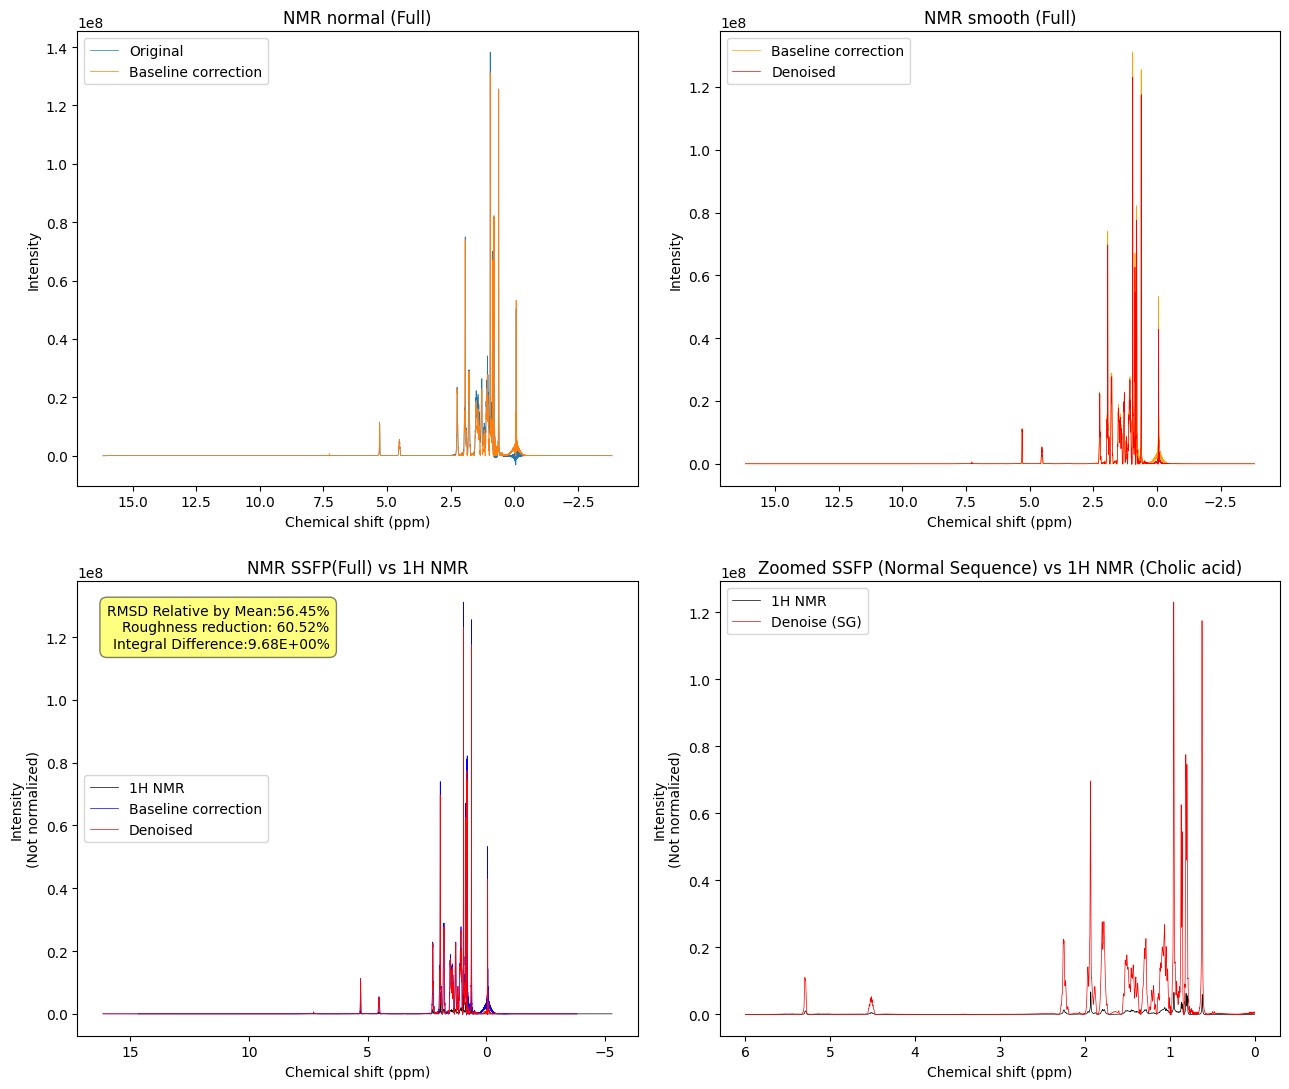



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              148580.874978    2650.537138    2650.115497   
Denoised              408723.506054  199053.624218  178988.422537   

          Max Equation  
Original   2519.347832  
Denoised  67966.023843  


In [ ]:
smooth_function('Cholic acid','Normal Sequence','Seq1_cholac_75°.csv','1H_cholac.csv',5,0.01,6,0,(10.0, 15.0),17,3,False)

###Sequence 2:
###SSFPdx_n2

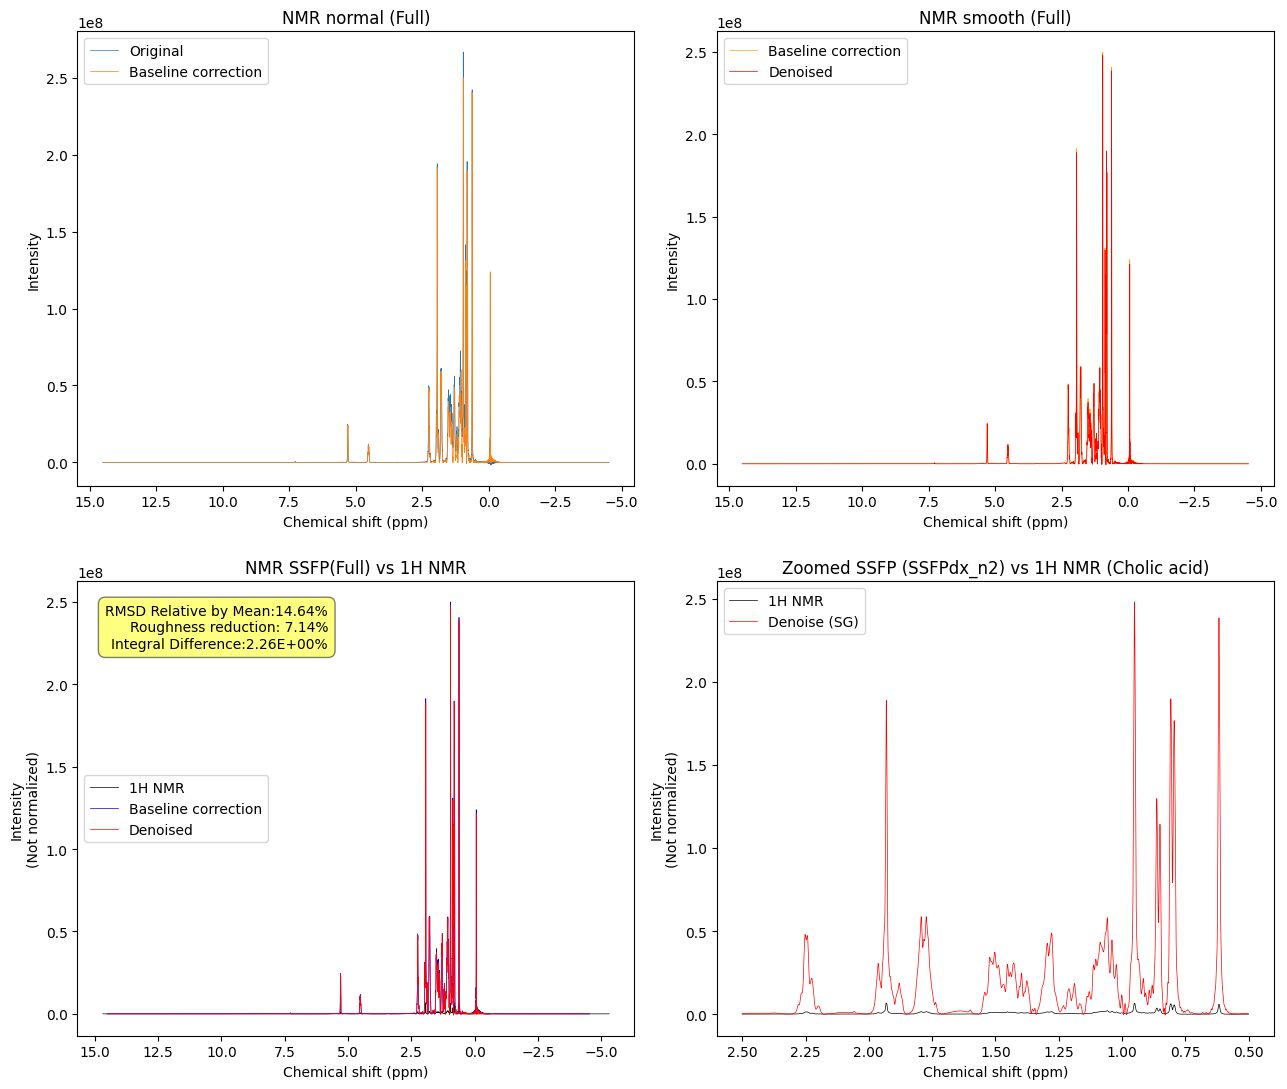



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              233946.539004   23253.849256   23139.819636   
Denoised              314697.329645  181966.695728  157551.299409   

          Max Equation  
Original  16918.715890  
Denoised  51232.289228  


In [ ]:
smooth_function('Cholic acid','SSFPdx_n2','Seq2_cholac_70°.csv','1H_cholac.csv',5,0.01,2.5,0.5,(10.0,14.0),19,4,False)

###Sequence 3
###SSFPdx_n4

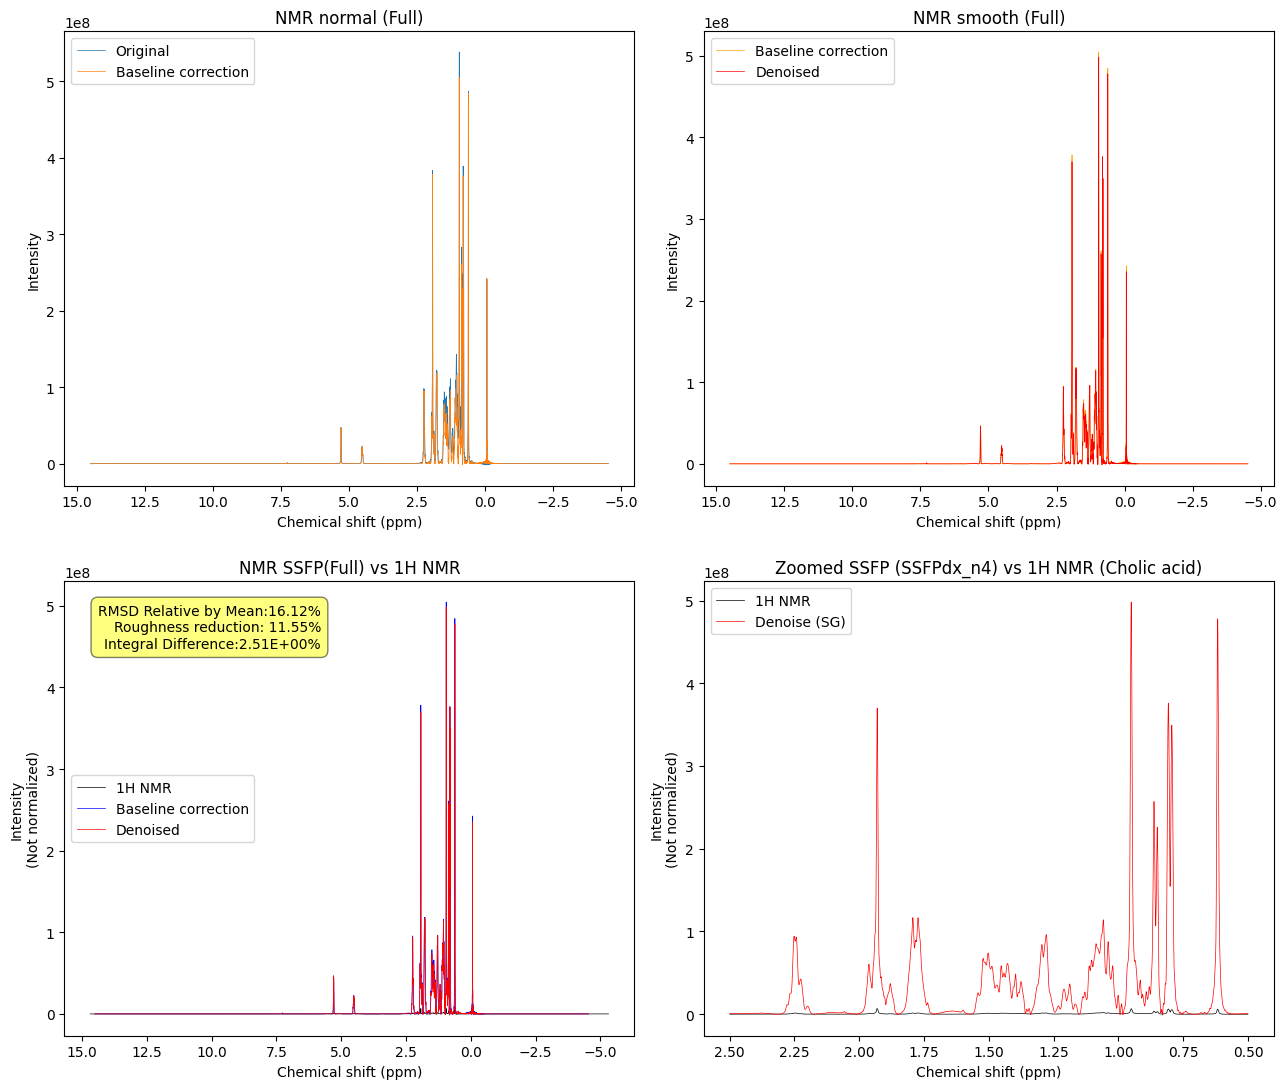



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              129200.257040   26406.897570   25887.485246   
Denoised              395860.813931  264291.602097  219833.694844   

          Max Equation  
Original  18152.946985  
Denoised  18995.611131  


In [ ]:
smooth_function('Cholic acid','SSFPdx_n4','Seq3_cholac_75°.csv','1H_cholac.csv',5,0.01,2.5,0.5,(9.0,14.0),21,4,False)

###Sequencia 4
###SSFPdx_n8

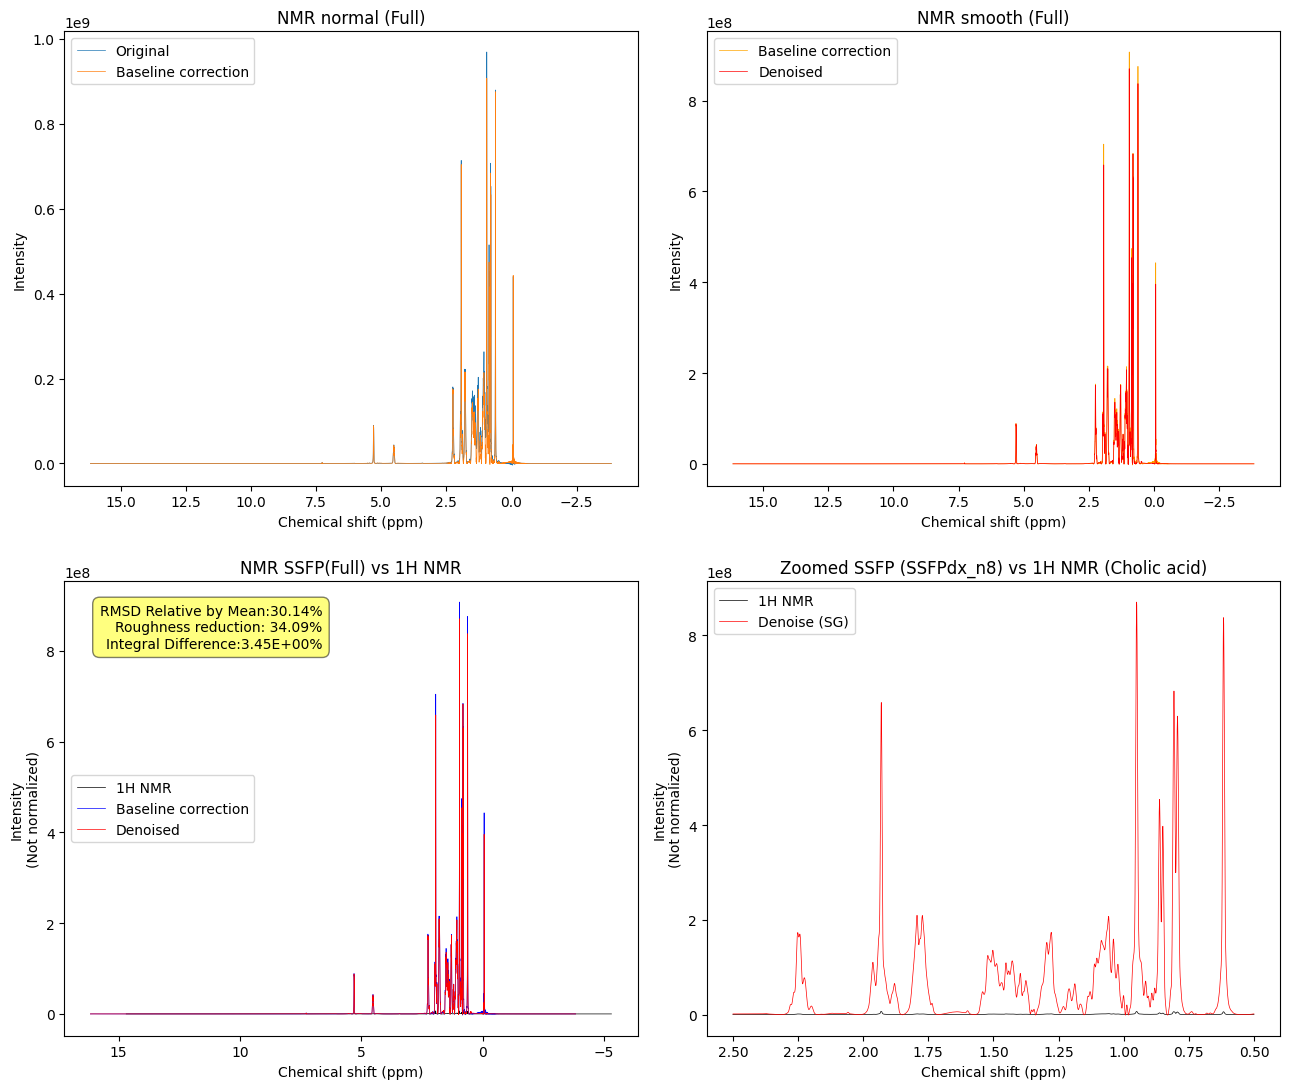



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               3.704783e+05  475965.128794  370078.403992   
Denoised               1.078707e+06  503147.128863  456059.273366   

           Max Equation  
Original   89505.075914  
Denoised  198700.268622  


In [ ]:
smooth_function('Cholic acid','SSFPdx_n8','Seq4_cholac_70°.csv','1H_cholac.csv',5,0.01,2.5,0.5,(10.0,15.0),27,4,False)

###Sequence 5:
###SSFPdxdt1024

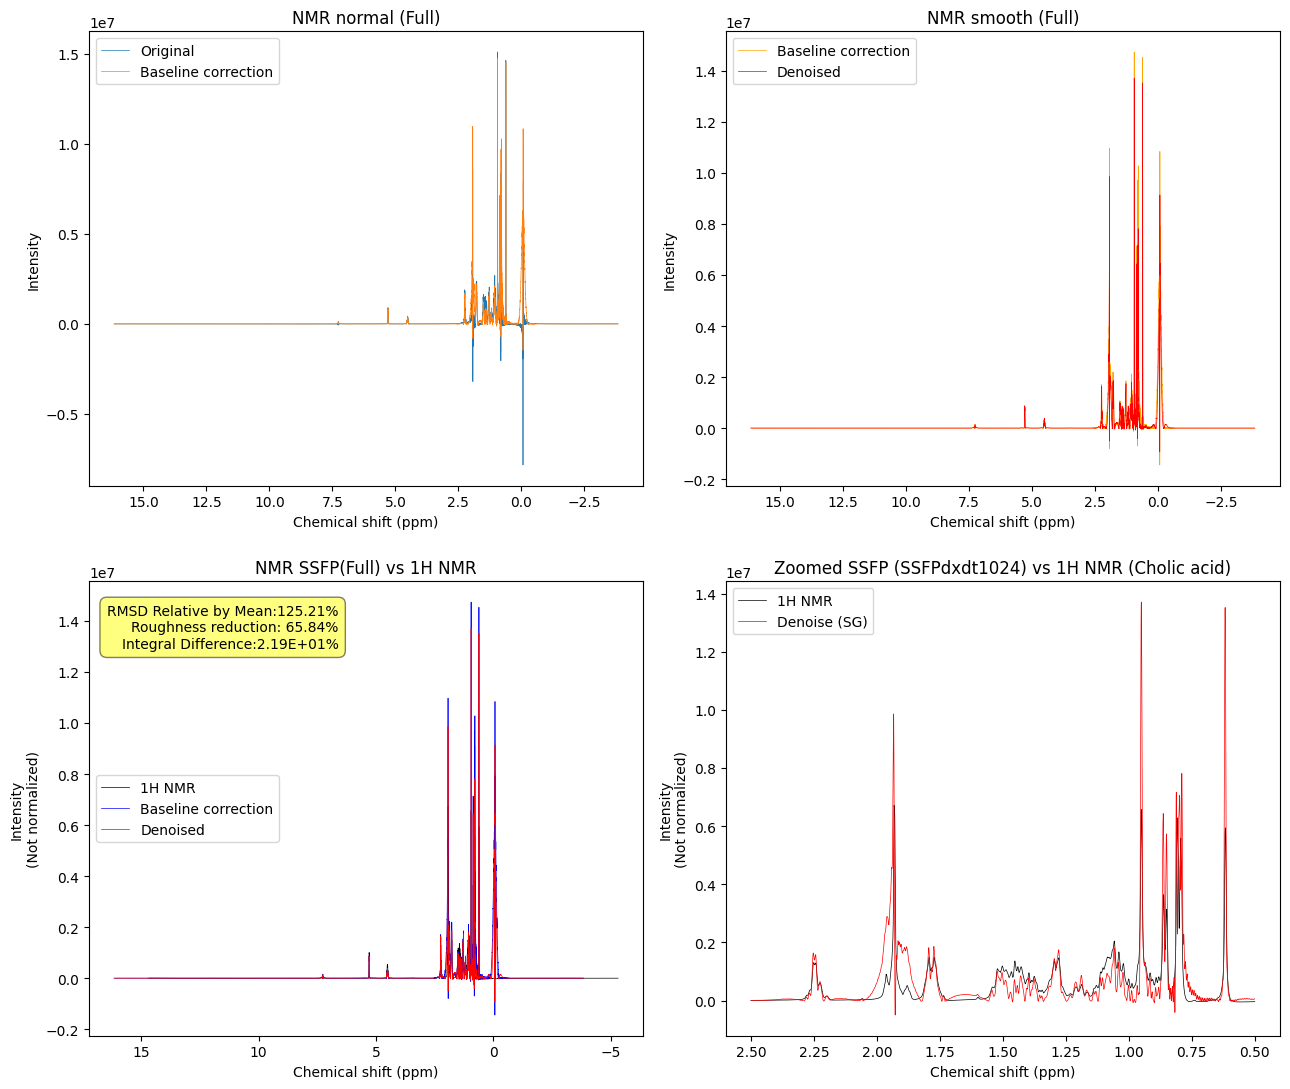



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  Max Equation
Original               34862.984252    2397.014519   2391.368837   1954.298137
Denoised               38812.015747   22586.706270  19603.108010   6512.747743


In [ ]:
smooth_function('Cholic acid','SSFPdxdt1024','Seq5_cholac_90°.csv','1H_cholac.csv',5,0.05,2.5,0.5,(10.0,15.0),25,4,False)

##For Cyclosporine

###Sequence 1
###Normal SSFP

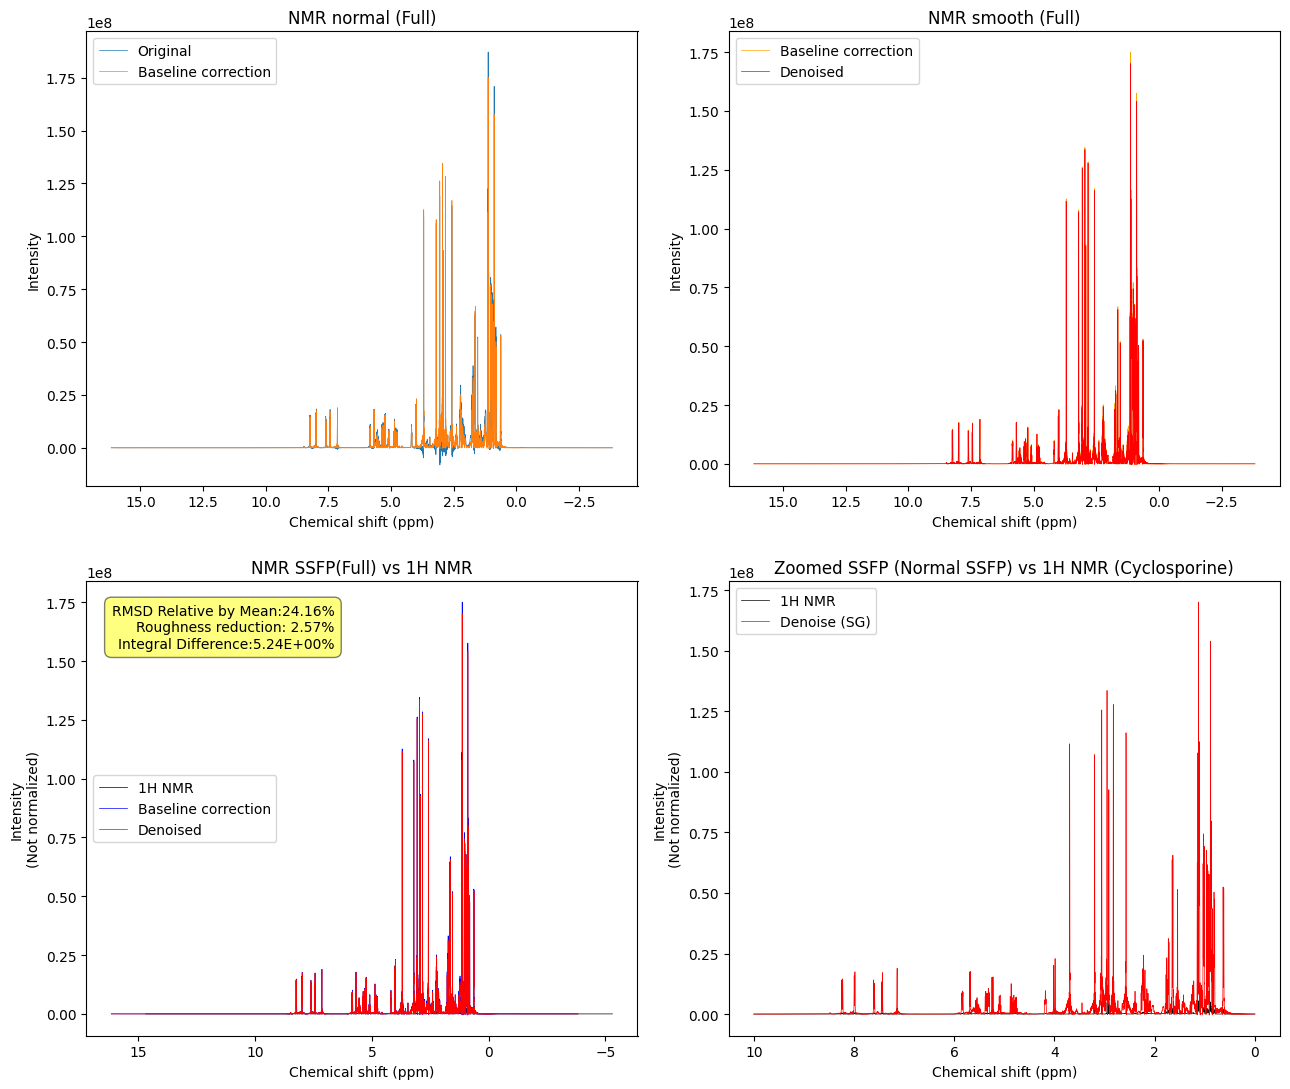



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  Max Equation
Original               48473.658971   62044.169234  47967.109147  10510.781984
Denoised               52434.564362   46260.462784  34693.609185   7280.128675


In [ ]:
smooth_function('Cyclosporine','Normal SSFP','Seq1_cyclosporine_70°.csv','1H_cyclosporine.csv',3,0.01,10,0,(10.0,16.0),13,4,False)

###Sequence 2
###SSFPdx_n2

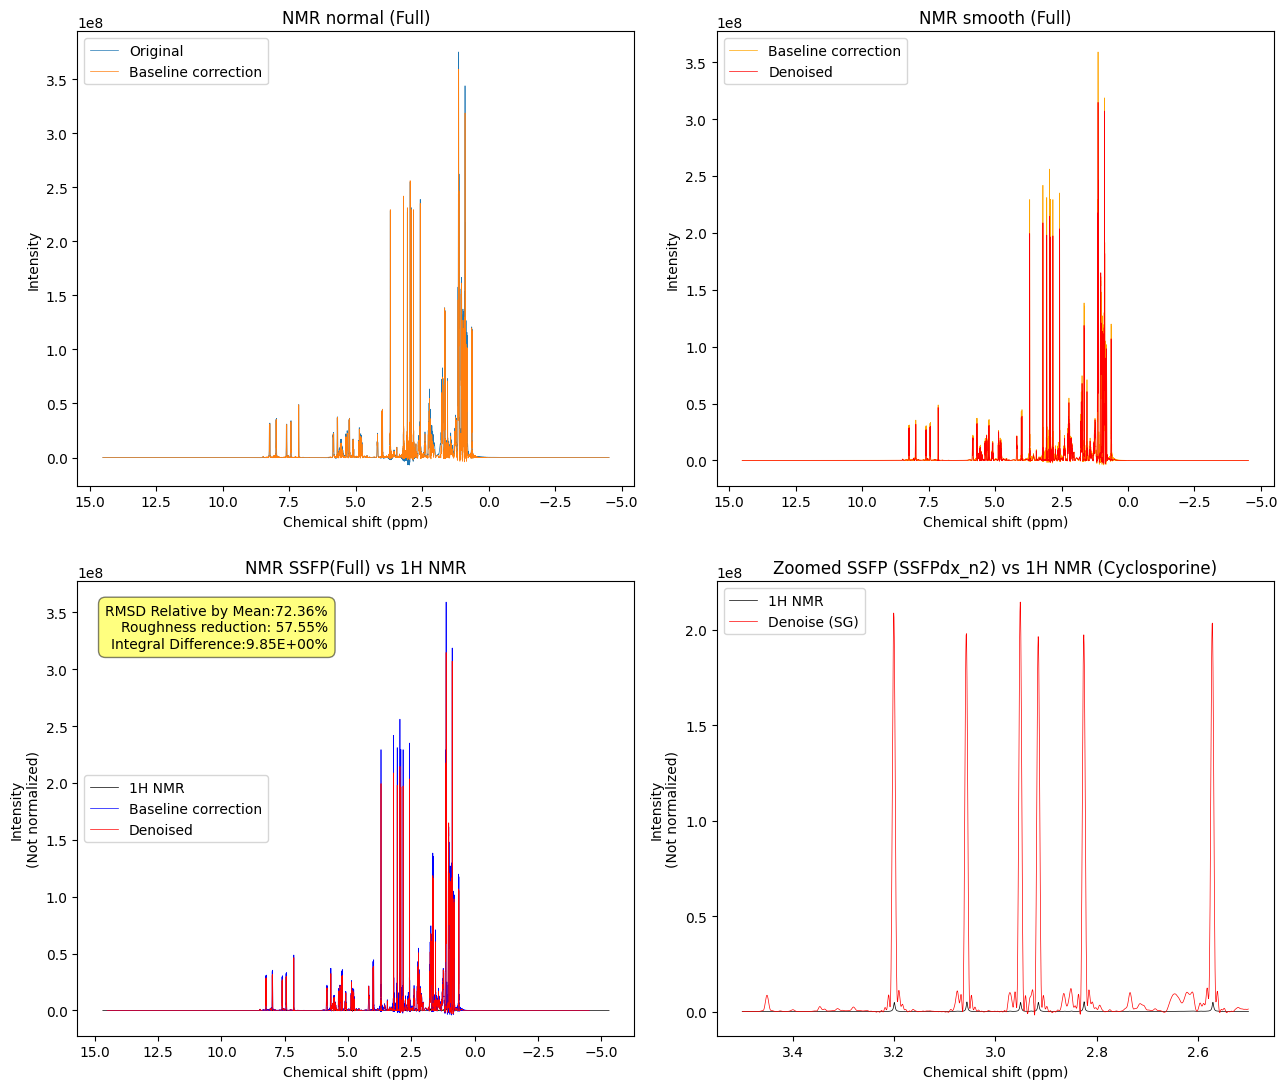



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               28696.379984    2739.988546    2727.583316   
Denoised              310412.150845  309486.853808  219544.998107   

          Max Equation  
Original   2256.562420  
Denoised  17607.977518  


In [ ]:
smooth_function('Cyclosporine','SSFPdx_n2','Seq2_cyclosporine_70°.csv','1H_cyclosporine.csv',5,0.04,3.5,2.5,(10.0,14.49),29,4,False)

###Sequence 3
###SSFPdx_n4

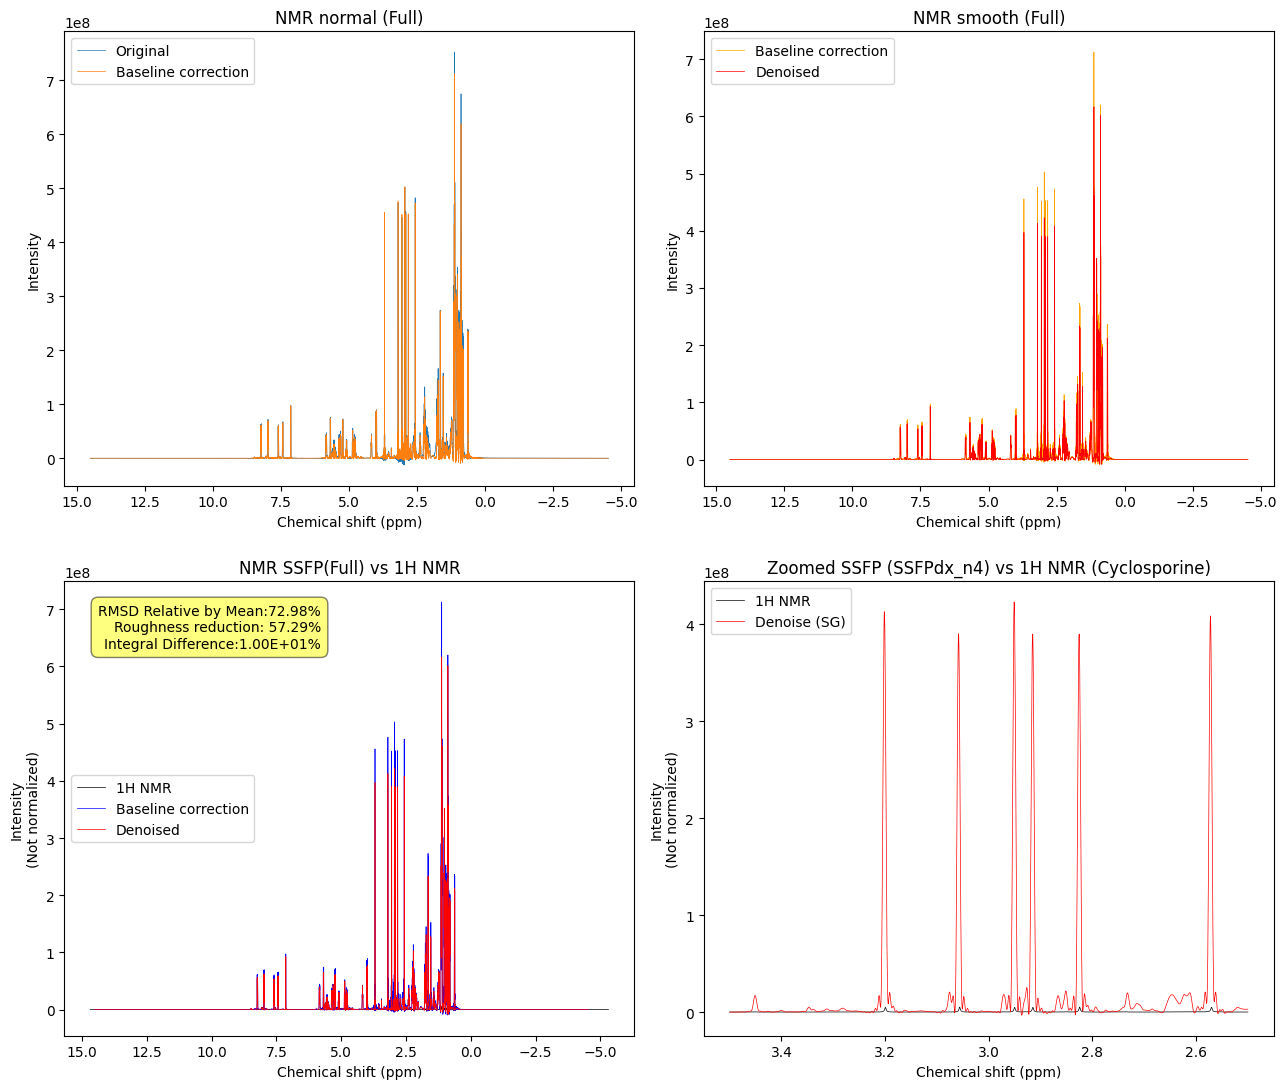



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               34151.101298    2143.007514    2138.800719   
Denoised              278927.905203  371537.361720  223504.712559   

          Max Equation  
Original   1548.701714  
Denoised  17414.566802  


In [ ]:
smooth_function('Cyclosporine','SSFPdx_n4','Seq3_cyclosporine_70°.csv','1H_cyclosporine.csv',5,0.05,3.5,2.5,(10.0,16.0),29,4,False)

###Sequence 4
###SSFPdx_n8

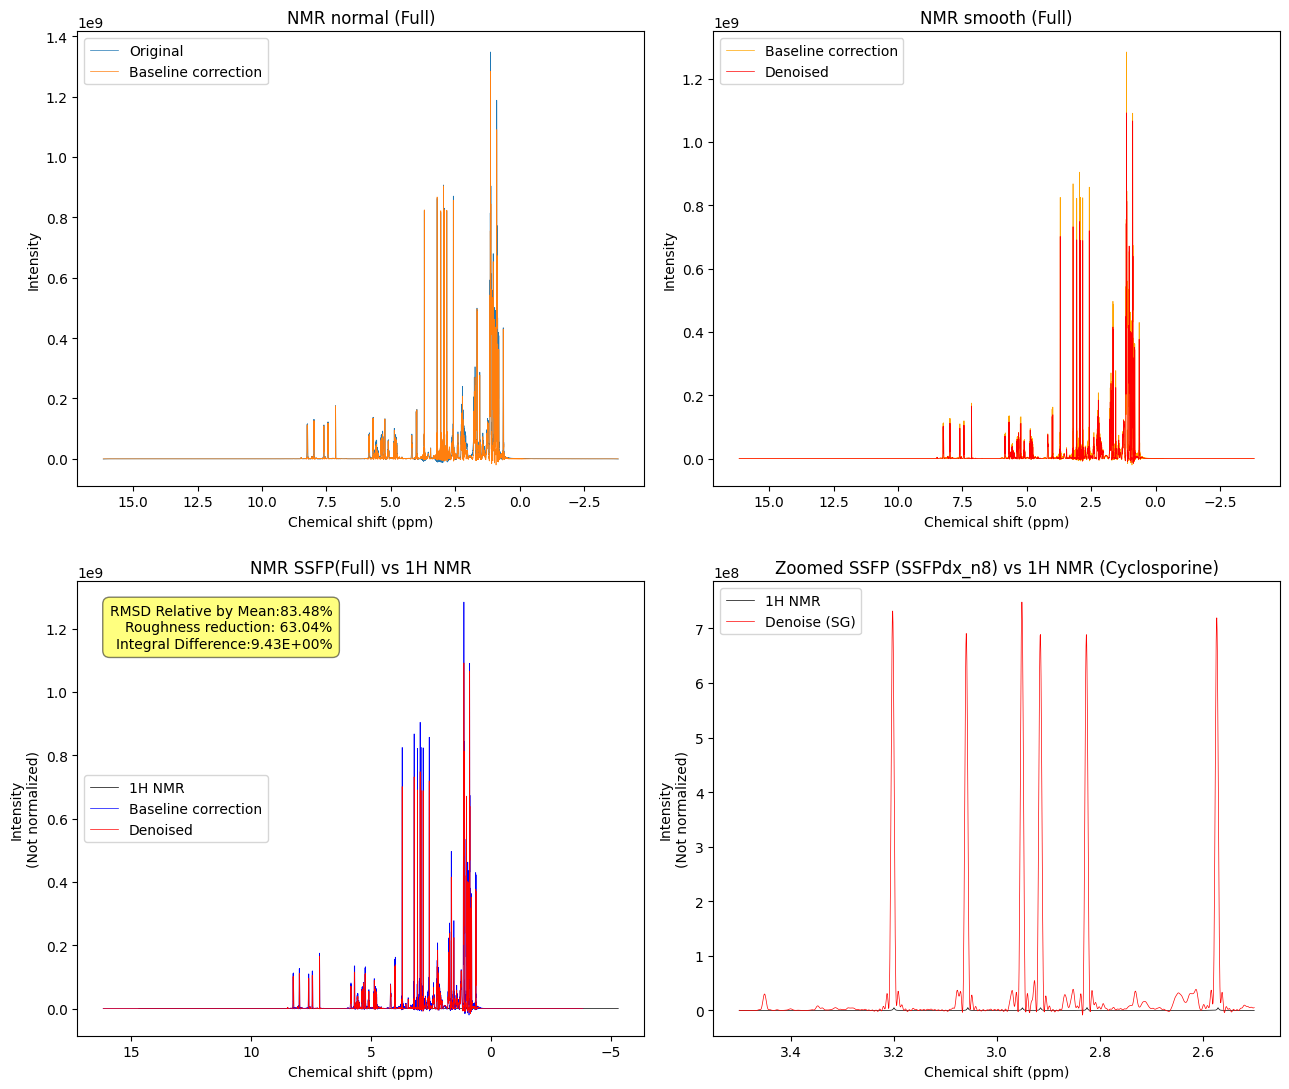



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               24972.528849   36954.183815   24272.788269   
Denoised              299257.111395  311420.065867  216346.580521   

          Max Equation  
Original   2609.359520  
Denoised  17014.624462  


In [ ]:
smooth_function('Cyclosporine','SSFPdx_n8','Seq4_cyclosporine_70°.csv','1H_cyclosporine.csv',5,0.05,3.5,2.5,(10.0,16.0),29,4,False)

###Sequence 5
###SSFPdxdt1024

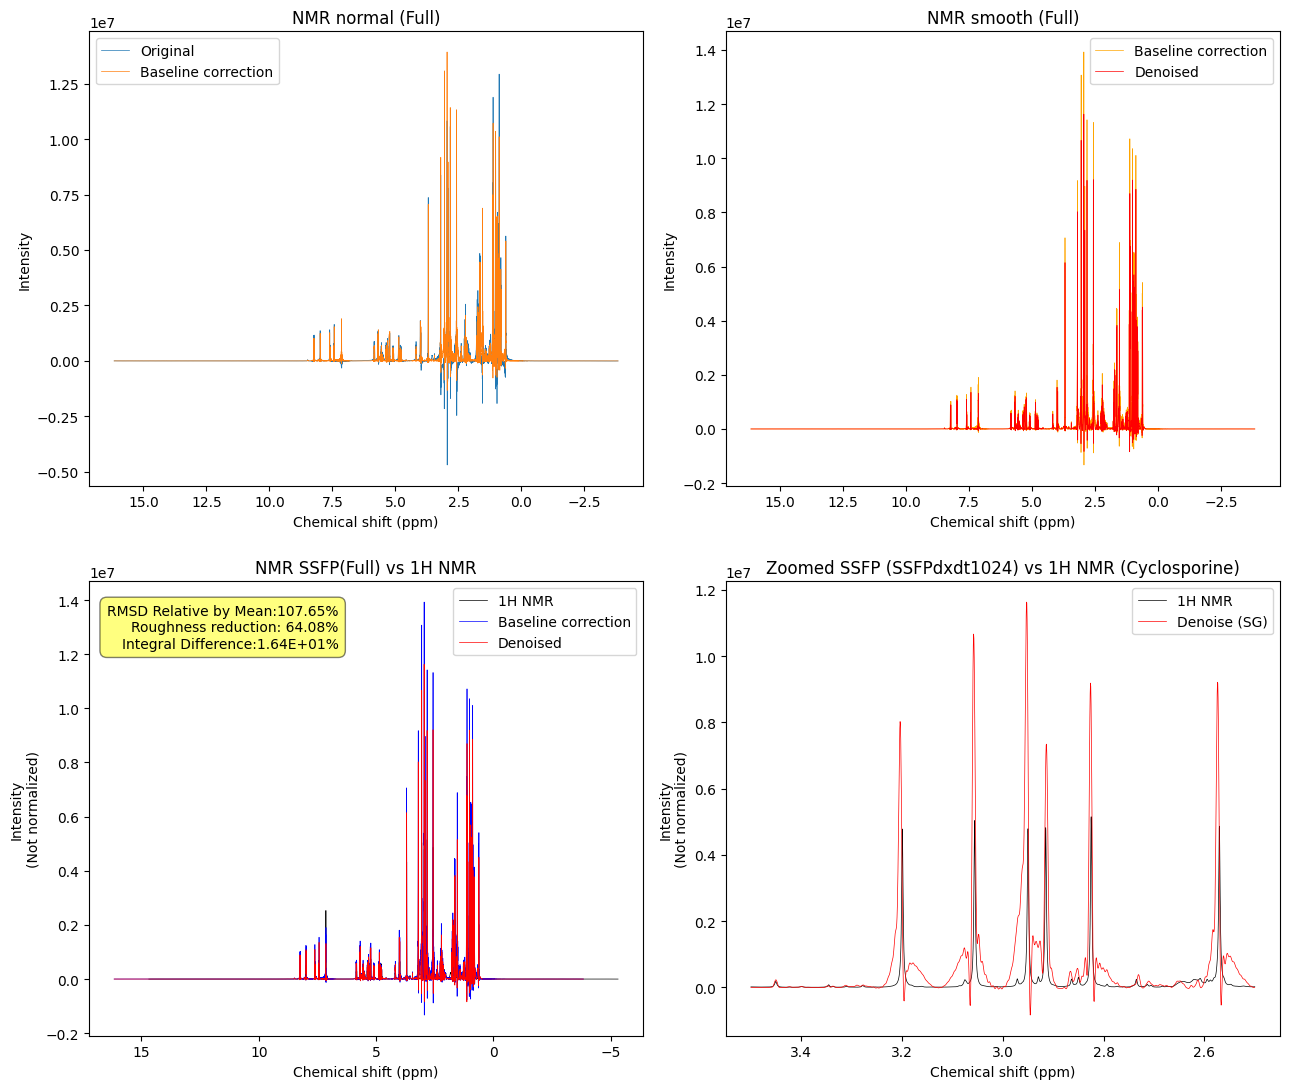



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  Max Equation
Original               18078.302405   20218.130081  16138.810804   4513.693087
Denoised               27690.787705   20043.391469  16443.832262   5237.964540


In [ ]:
smooth_function('Cyclosporine','SSFPdxdt1024','Seq5_cyclosporine_65°.csv','1H_cyclosporine.csv',4,0.09,3.5,2.5,(10.0,16.0),29,4,False)

##For Ethylbenzene (EB)

###Sequence 1
###Normal SSFP

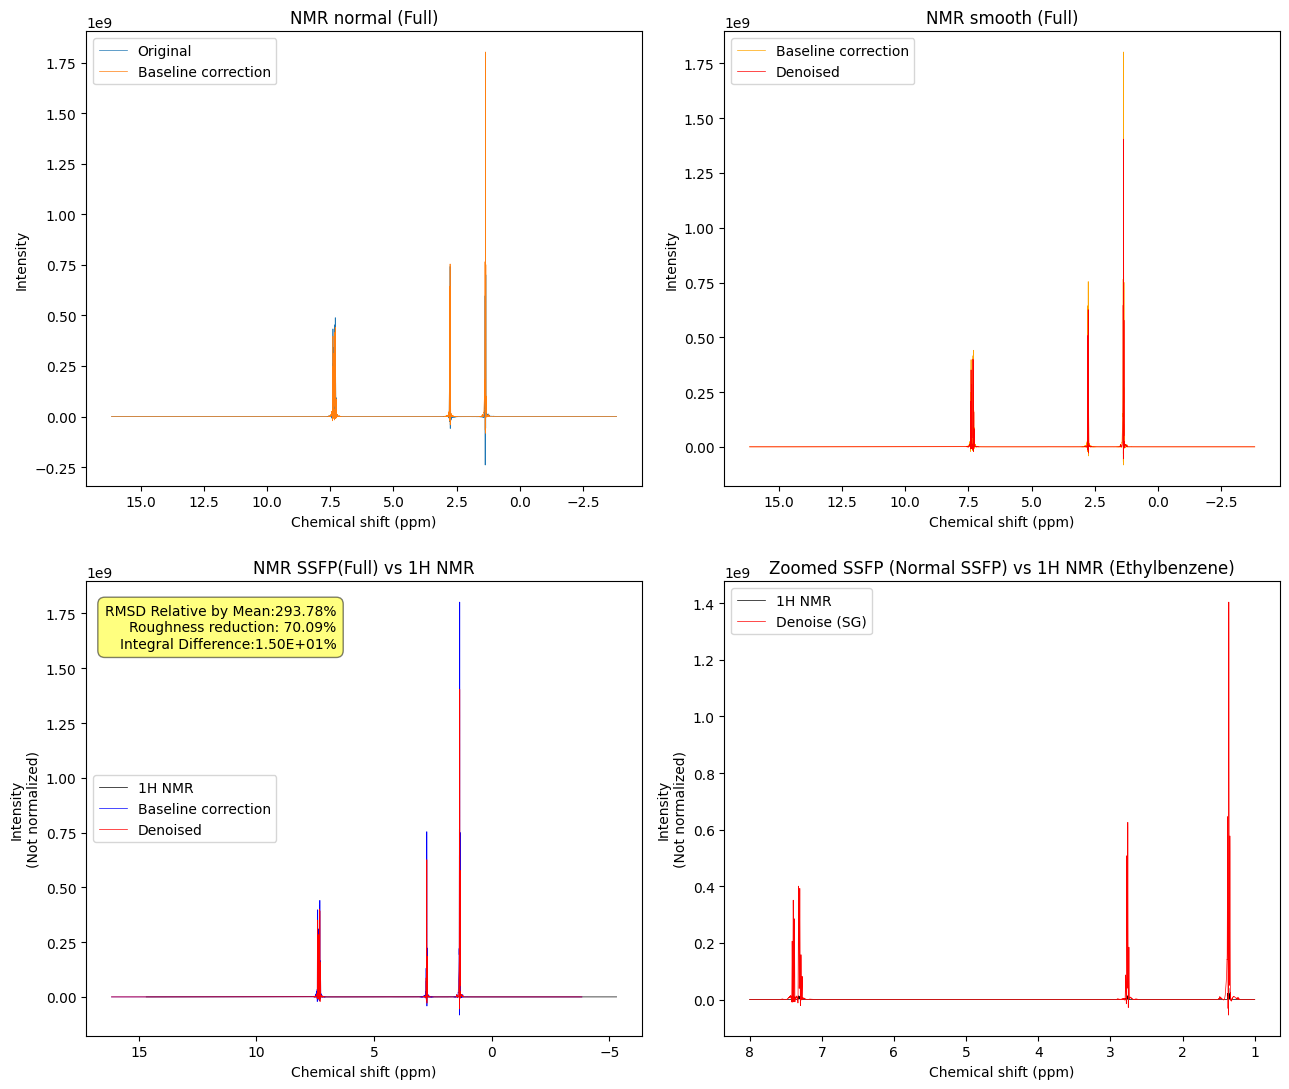



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              255010.749547  551728.250300  254931.642519   
Denoised              394258.409344  958268.643797  365625.554199   

          Max Equation  
Original  14708.230702  
Denoised  18544.997819  


In [ ]:
smooth_function('Ethylbenzene','Normal SSFP','Seq1_EB_30°.csv','1H_EB.csv',4,0.09,8,1,(8.00,14.30),17,2,False)

###Sequence 2
###SSFPdx_n2

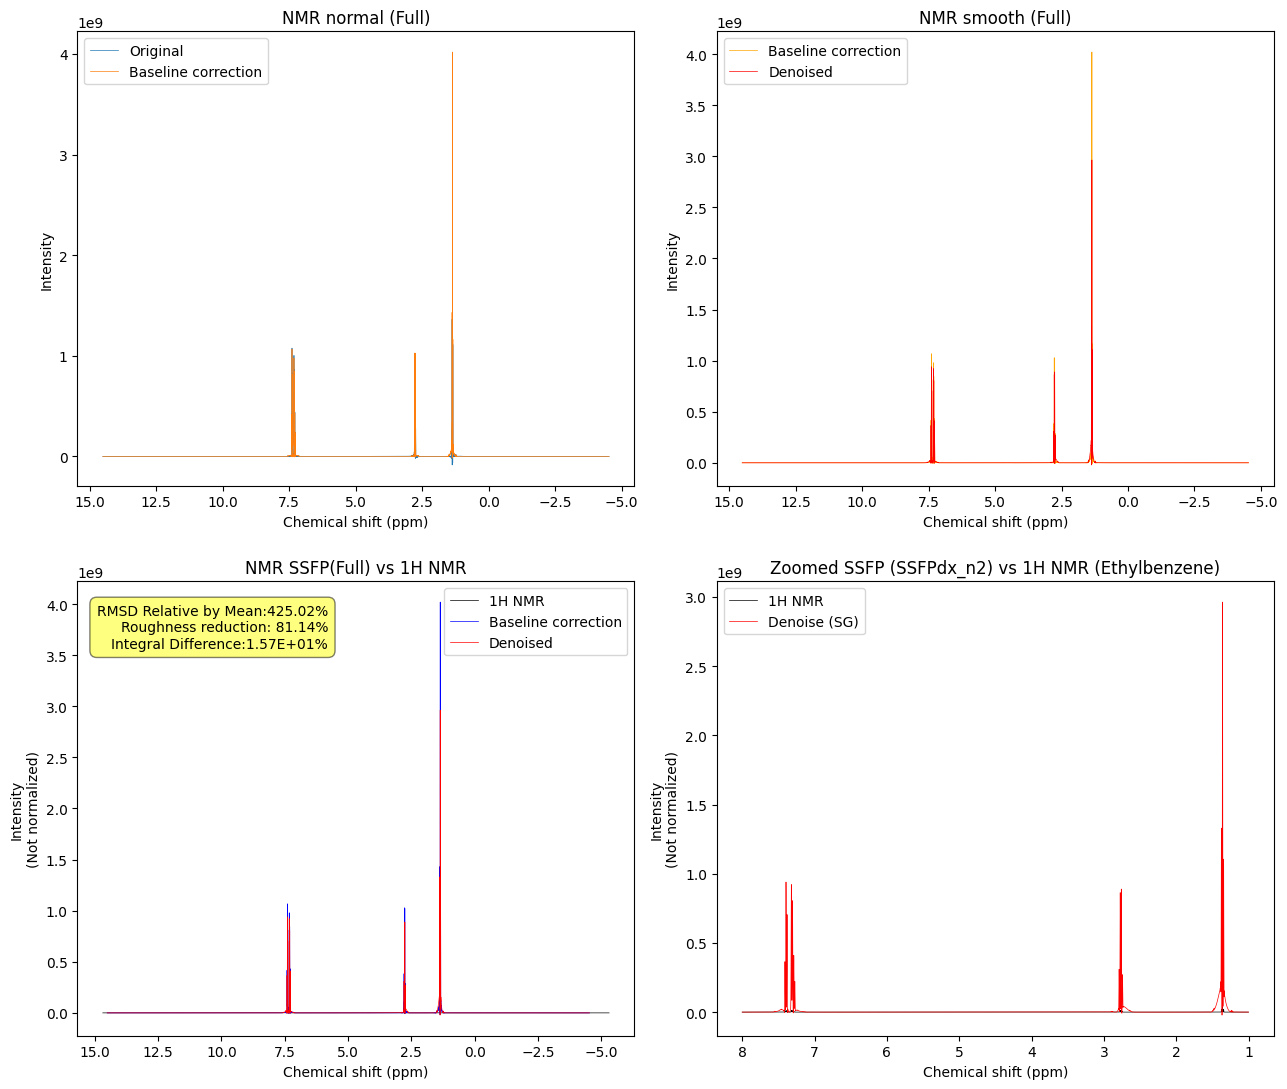



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              194682.683935   1.849932e+05  150768.237978   
Denoised              495666.393380   1.107513e+06  452486.620106   

          Max Equation  
Original  29926.915779  
Denoised  24501.775793  


In [ ]:
smooth_function('Ethylbenzene','SSFPdx_n2','Seq2_EB_40°.csv','1H_EB.csv',4,0.02,8,1,(8.00,14.30),29,5,False)

###Sequence 3
###SSFPdx_n4

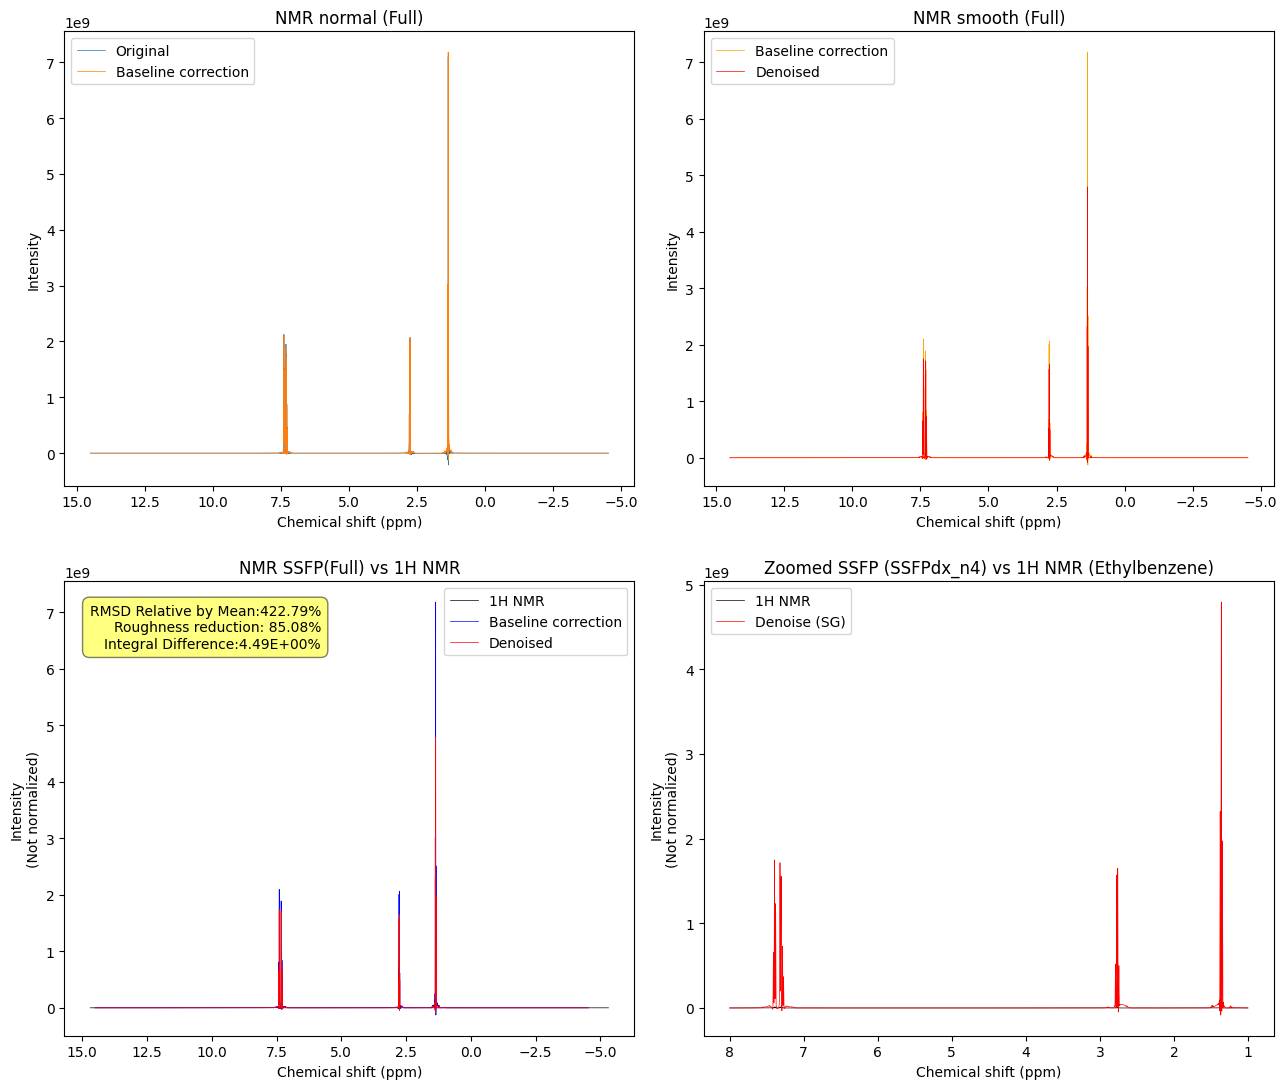



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              196328.032205   1.594798e+05  133011.661388   
Denoised              401048.371733   1.234915e+06  381641.712069   

          Max Equation  
Original  26261.199254  
Denoised  21439.945328  


In [ ]:
smooth_function('Ethylbenzene','SSFPdx_n4','Seq3_EB_40°.csv','1H_EB.csv',5,0.05,8,1,(8.00,14.30),21,3,False)

###Sequence 4
###SSFPdx_n8

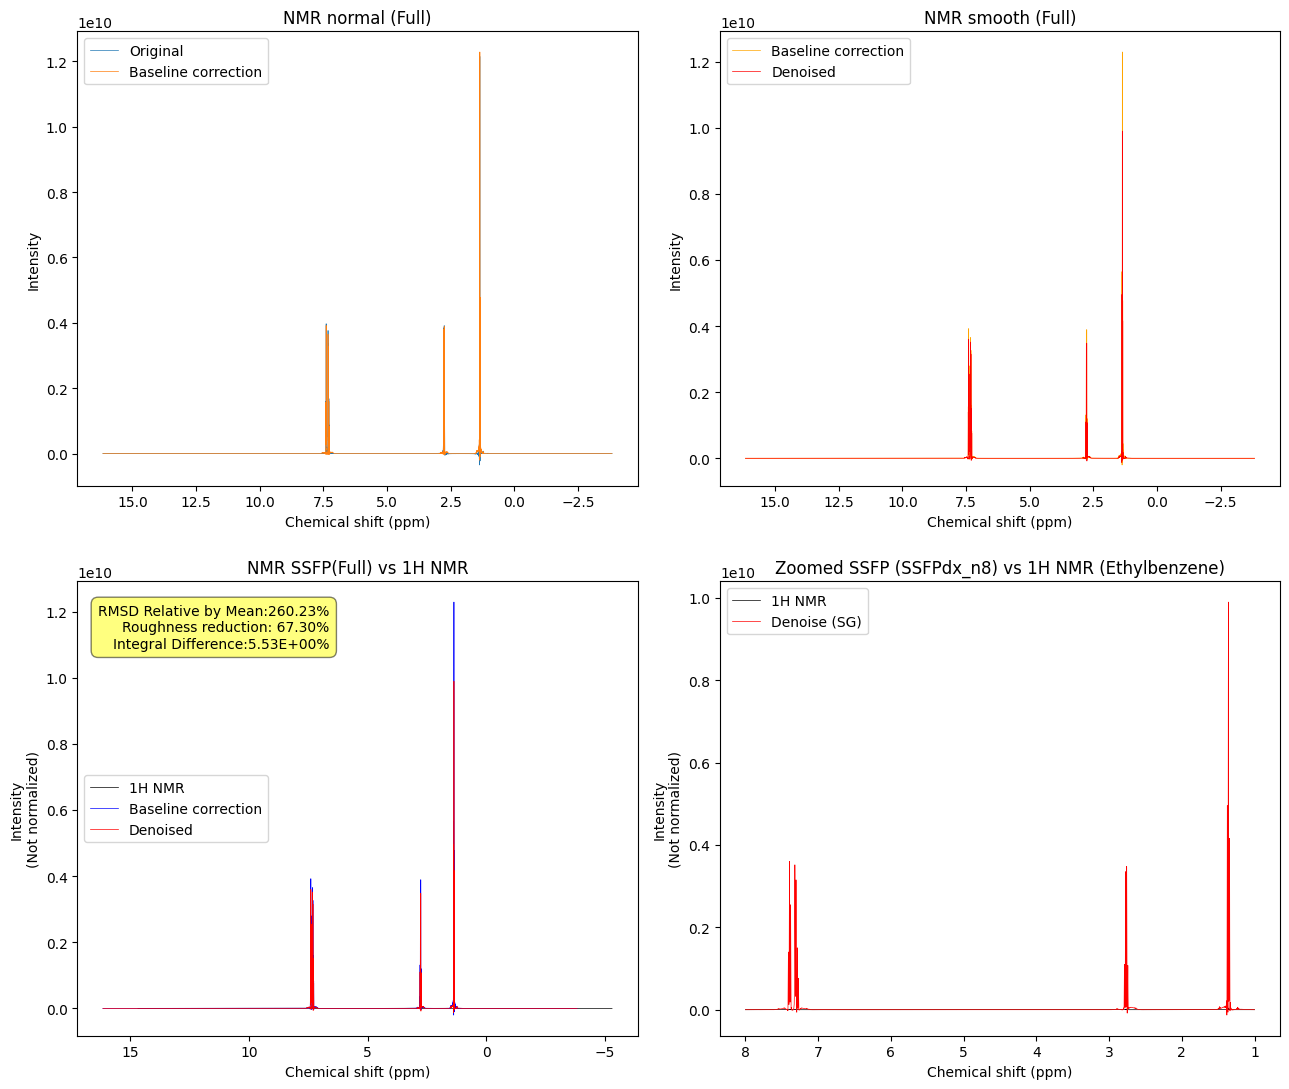



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              128603.251711   1.802882e+05  127611.962454   
Denoised              421356.428658   1.502497e+06  405869.363726   

          Max Equation  
Original  15644.625968  
Denoised  21725.091394  


In [ ]:
smooth_function('Ethylbenzene','SSFPdx_n8','Seq4_EB_35°.csv','1H_EB.csv',5,0.05,8,1,(8.00,14.30),25,4,False)

###Sequence 5
###SSFPdxdt1024

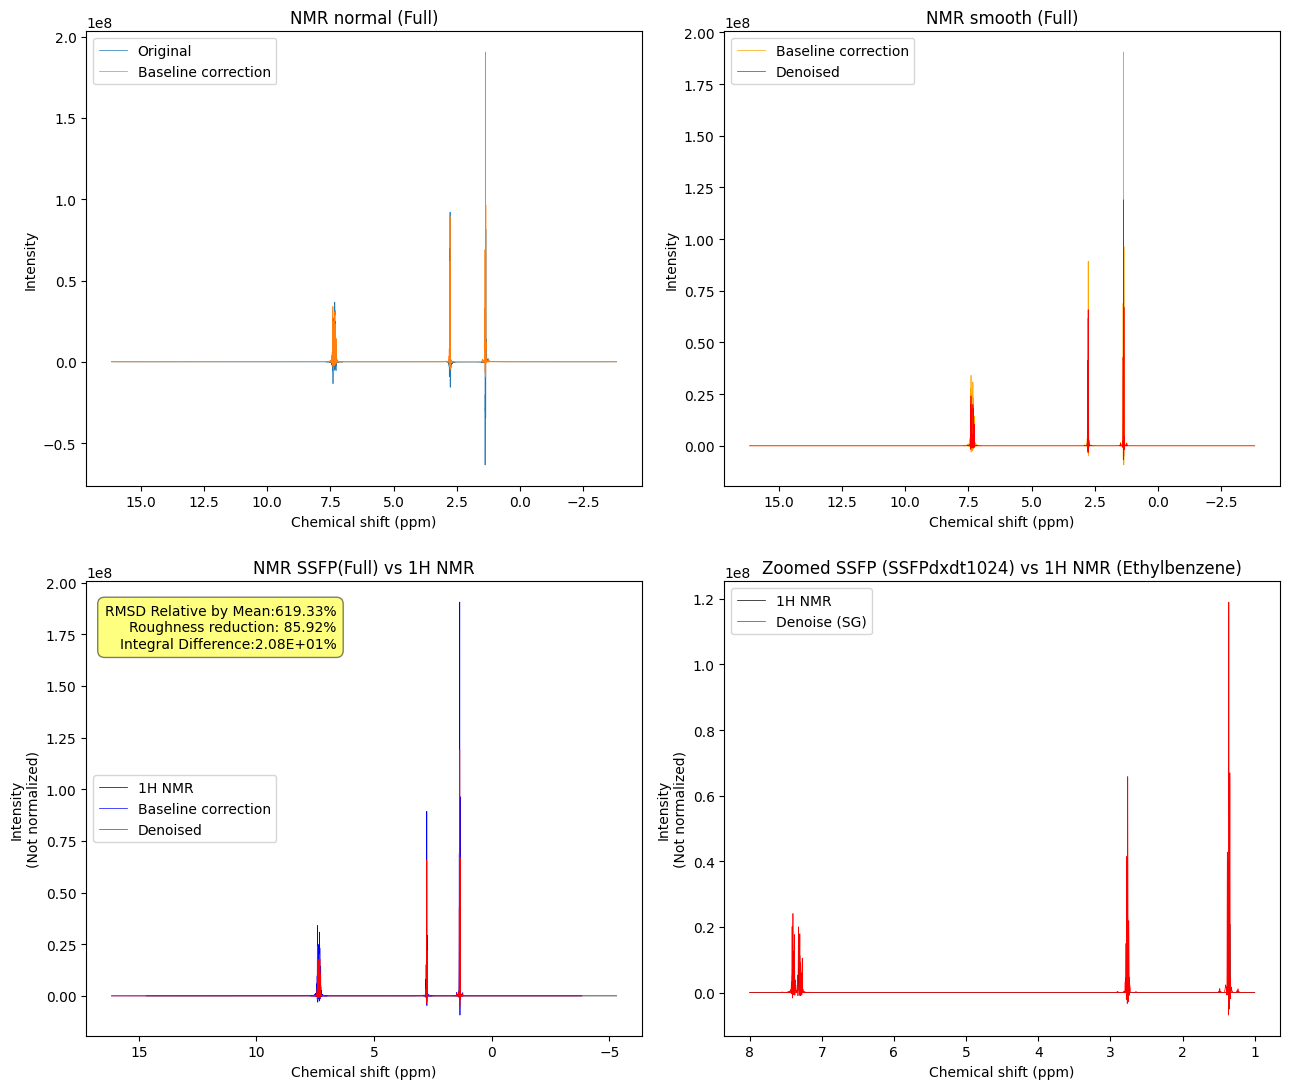



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original              106053.757683   58306.323888   54207.253415   
Denoised              203560.427445  207400.581739  147020.880755   

          Max Equation  
Original  10514.510449  
Denoised  16576.511739  


In [ ]:
smooth_function('Ethylbenzene','SSFPdxdt1024','Seq5_EB_40°.csv','1H_EB.csv',2,0.1,8,1,(8.00,14.30),37,6,False)

##For Pamoic Acid

###Sequence 1
###Normal SSFP

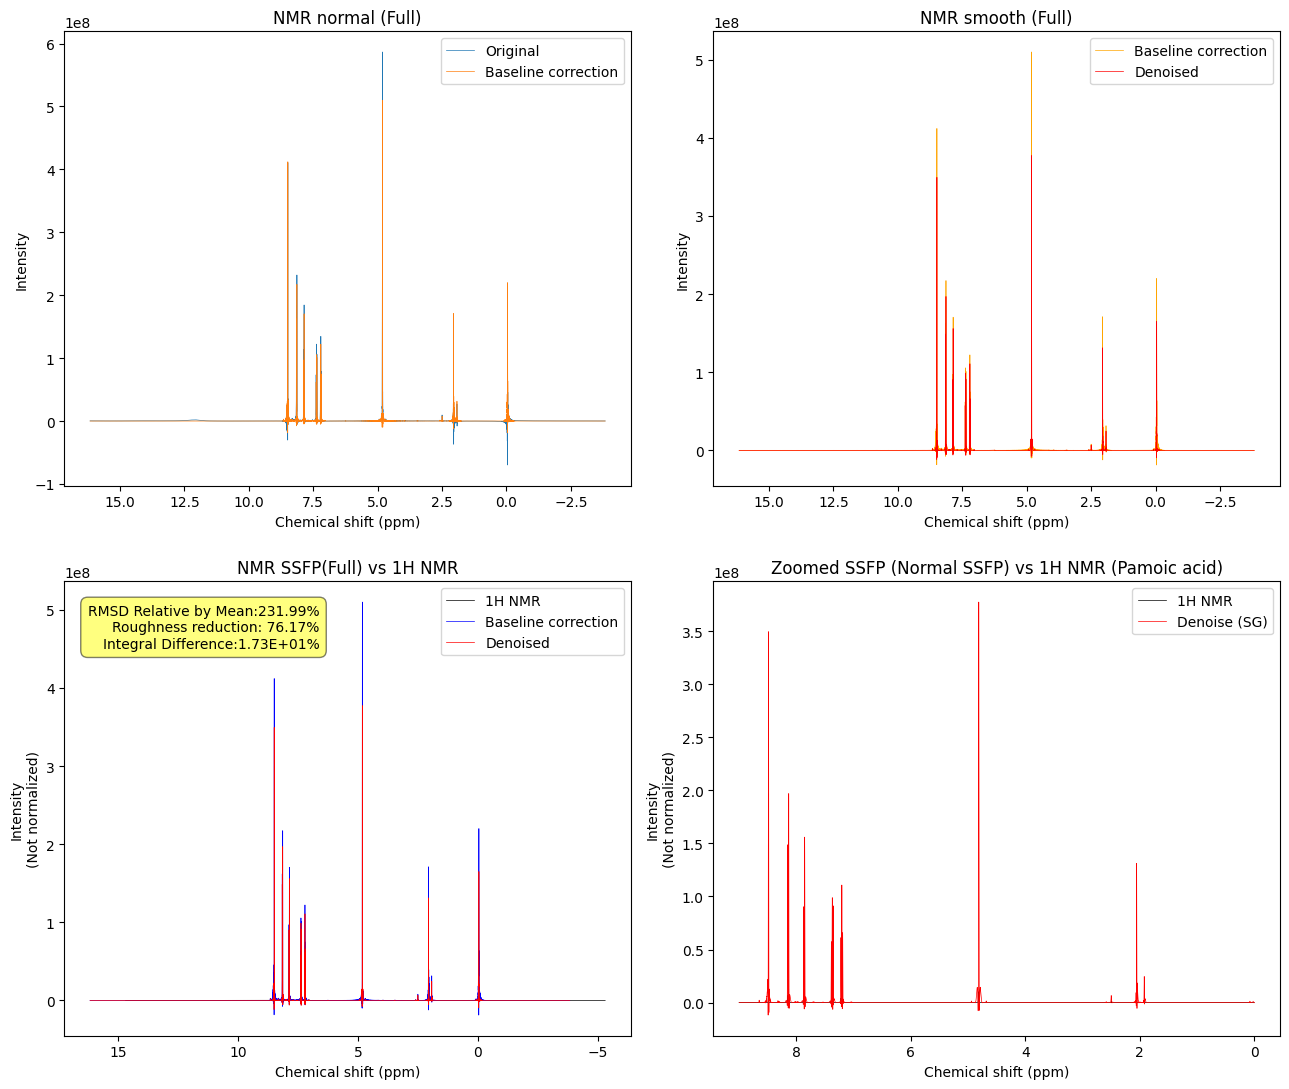



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               11272.331109     607.455944     606.575823   
Denoised              235183.339150  143249.010653  124713.102862   

          Max Equation  
Original    537.330406  
Denoised  65119.481665  


In [ ]:
smooth_function('Pamoic acid','Normal SSFP','Seq1_pamoic acid_70°.csv','1H-pamoic _acid.csv',3,0.102,9,0,(-0.6,-0.5),27,4,False)

###Sequence 2
###SSFPdx_n2

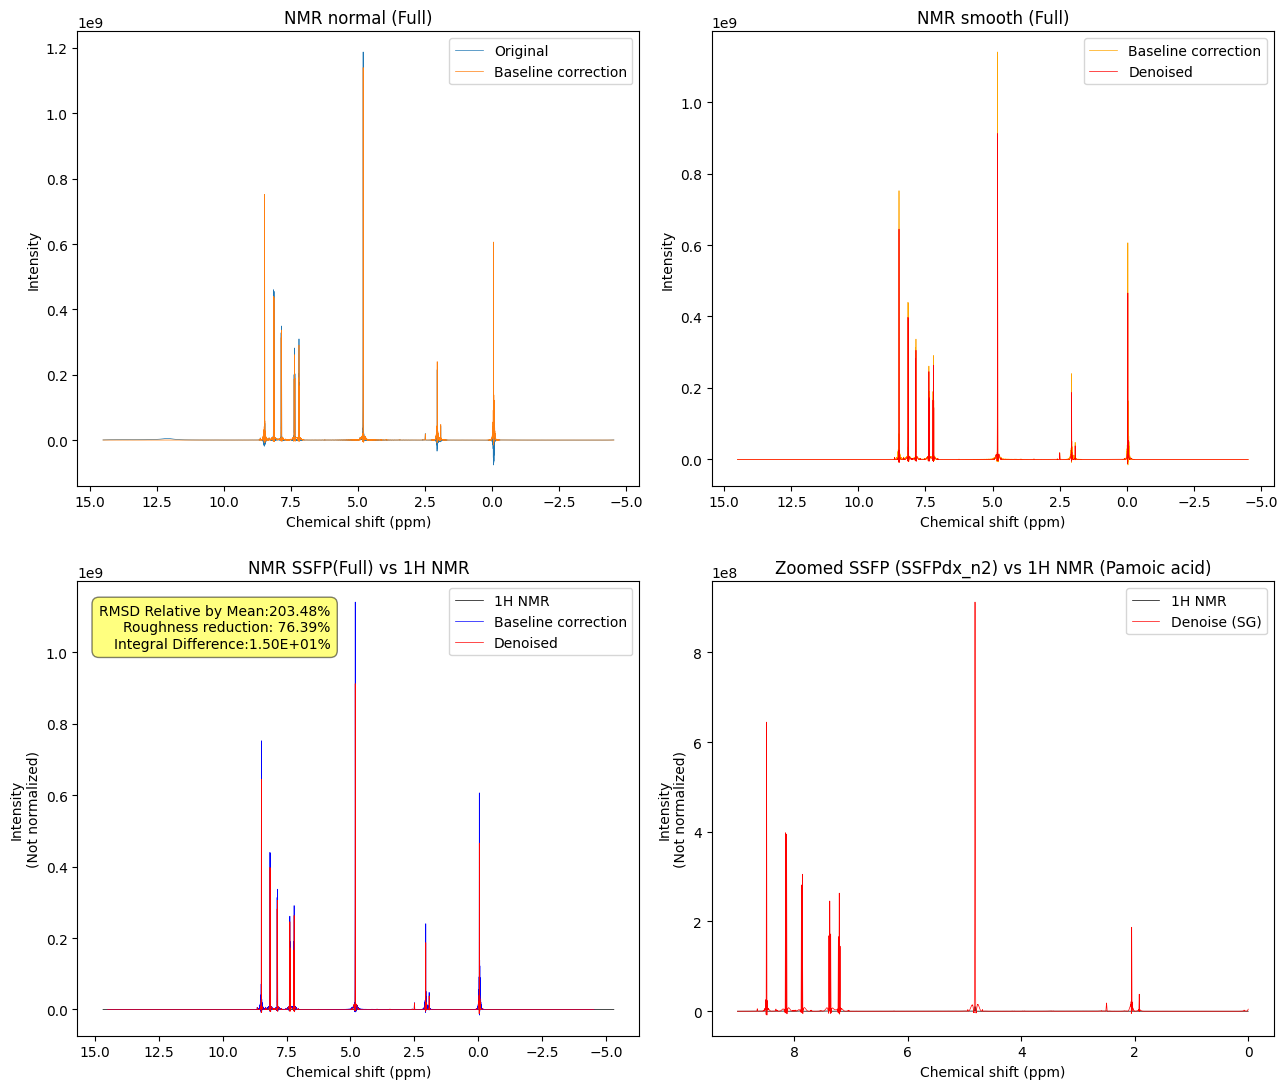



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               25928.876074   30511.851244   25905.189879   
Denoised              289199.027462  191602.737061  160504.054580   

          Max Equation  
Original  13011.908720  
Denoised  89068.596708  


In [ ]:
smooth_function('Pamoic acid','SSFPdx_n2',"Seq2_pamoic acid_60°.csv","1H-pamoic _acid.csv",4,0.06,9,0,(-0.6,-0.5),29,4,False)

###Sequence 3
###SSFPdx_n4

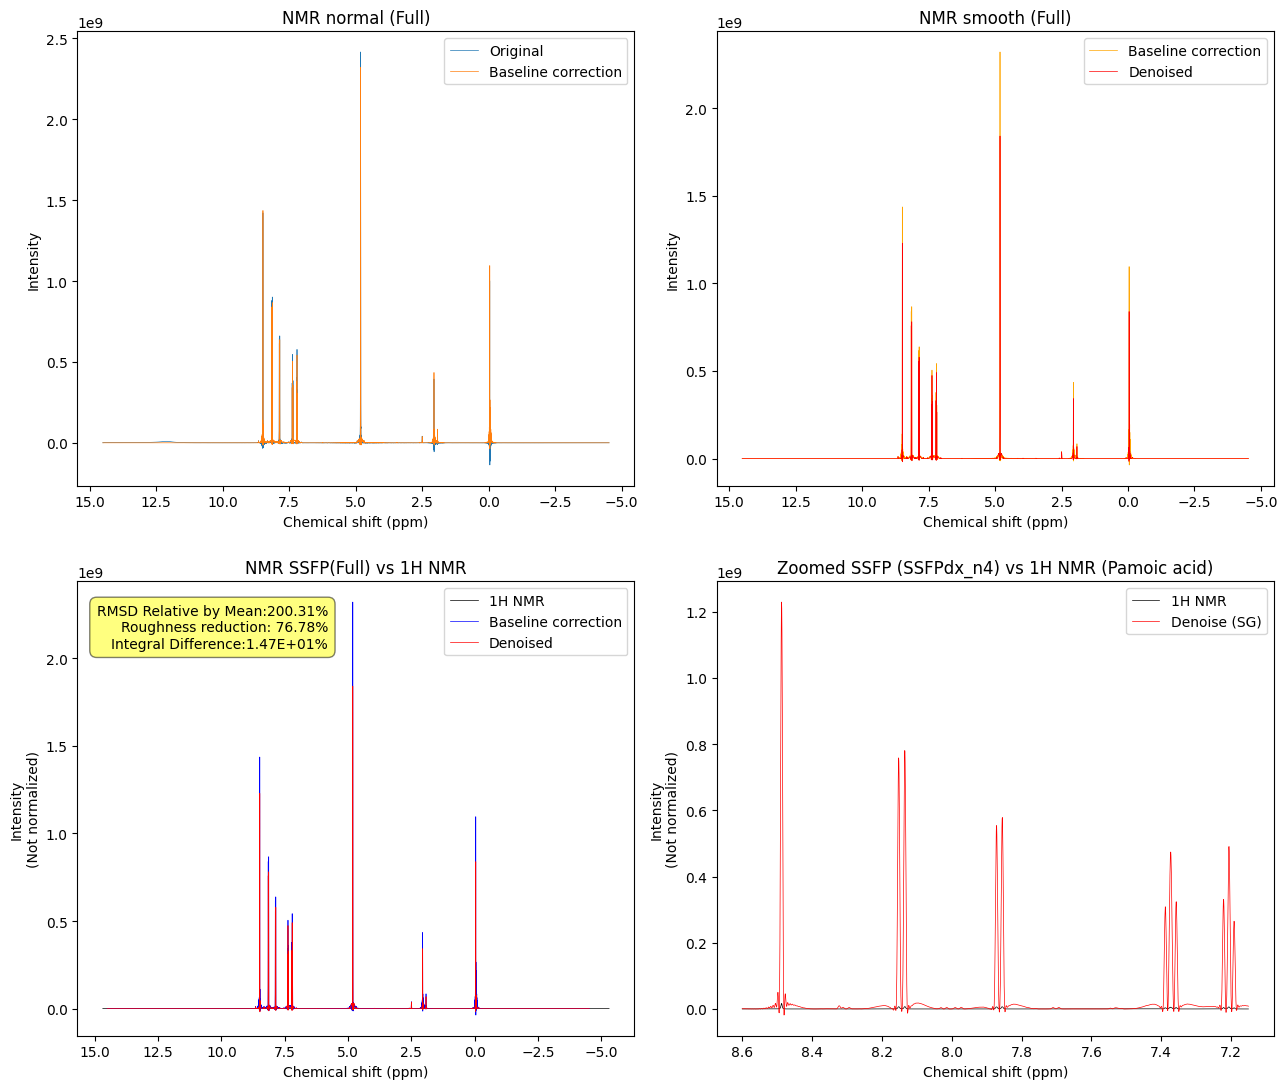



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               27355.622673     7883.38290    7575.105037   
Denoised              288673.902060   195056.97211  162421.809264   

          Max Equation  
Original   4954.724403  
Denoised  91097.493327  


In [ ]:
smooth_function('Pamoic acid','SSFPdx_n4','Seq3_pamoic acid_65°.csv','1H-pamoic _acid.csv',4,0.06,8.6,7.15,(-0.6,-0.5),29,5,False)

###Sequence 4
###SSFPdx_n8

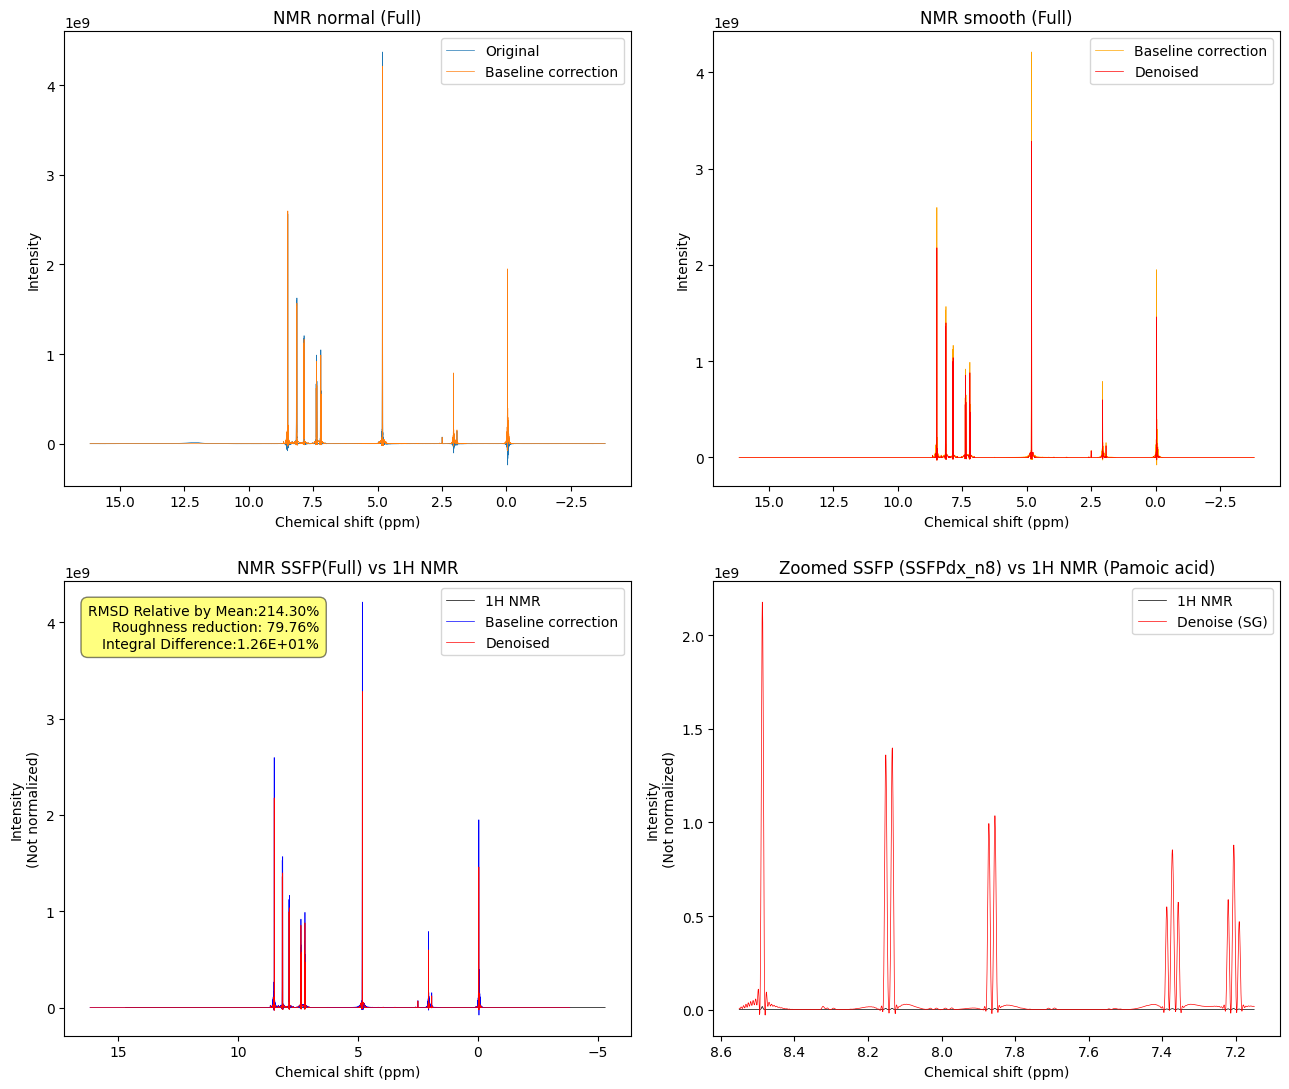



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  Max Equation
Original               27741.143829   11908.911620  10943.179816   6246.019666
Denoised              170229.633267  119052.384392  98109.981222  50527.971415


In [ ]:
smooth_function('Pamoic acid','SSFPdx_n8','Seq4_pamoic acid_65°.csv','1H-pamoic _acid.csv',4,0.06,8.55,7.15,(-0.6,-0.5),29,5,False)

###Sequence 5
###SSFPdxdt1024

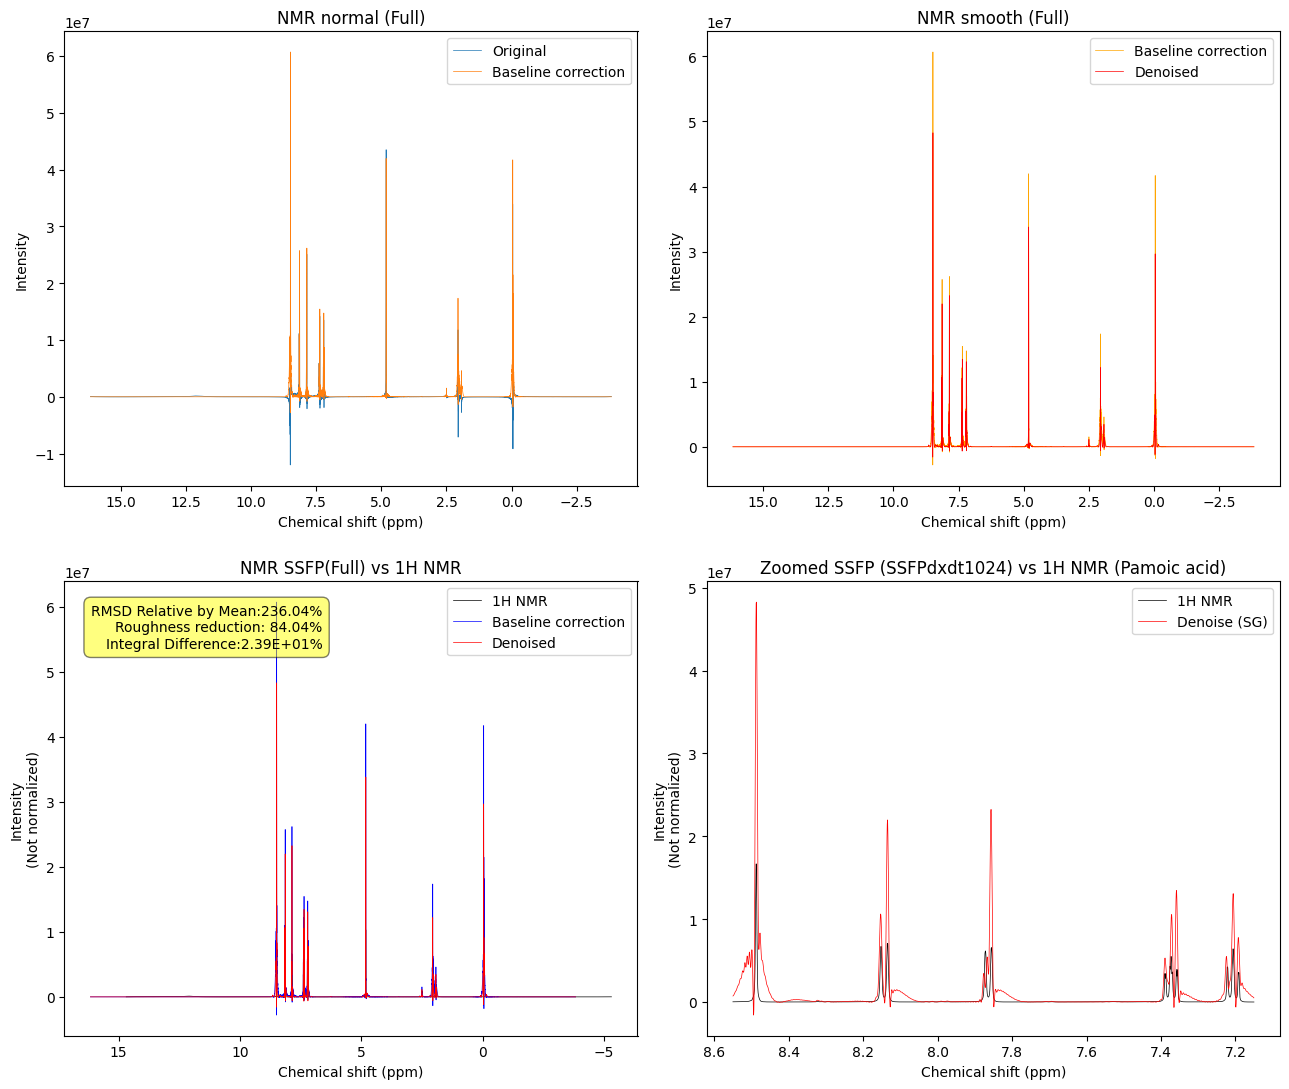



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  Max Equation
Original                5067.145046     861.350612    849.169311    616.828046
Denoised               38293.584757   23647.049914  20214.528272  10268.000677


In [ ]:
smooth_function('Pamoic acid','SSFPdxdt1024','Seq5_pamoic acid_55°.csv','1H-pamoic _acid.csv',4,0.06,8.55,7.15,(-0.6,-0.5),29,5,False)

##For Xanthan Gum

###Sequence 1
###Normal SSFP

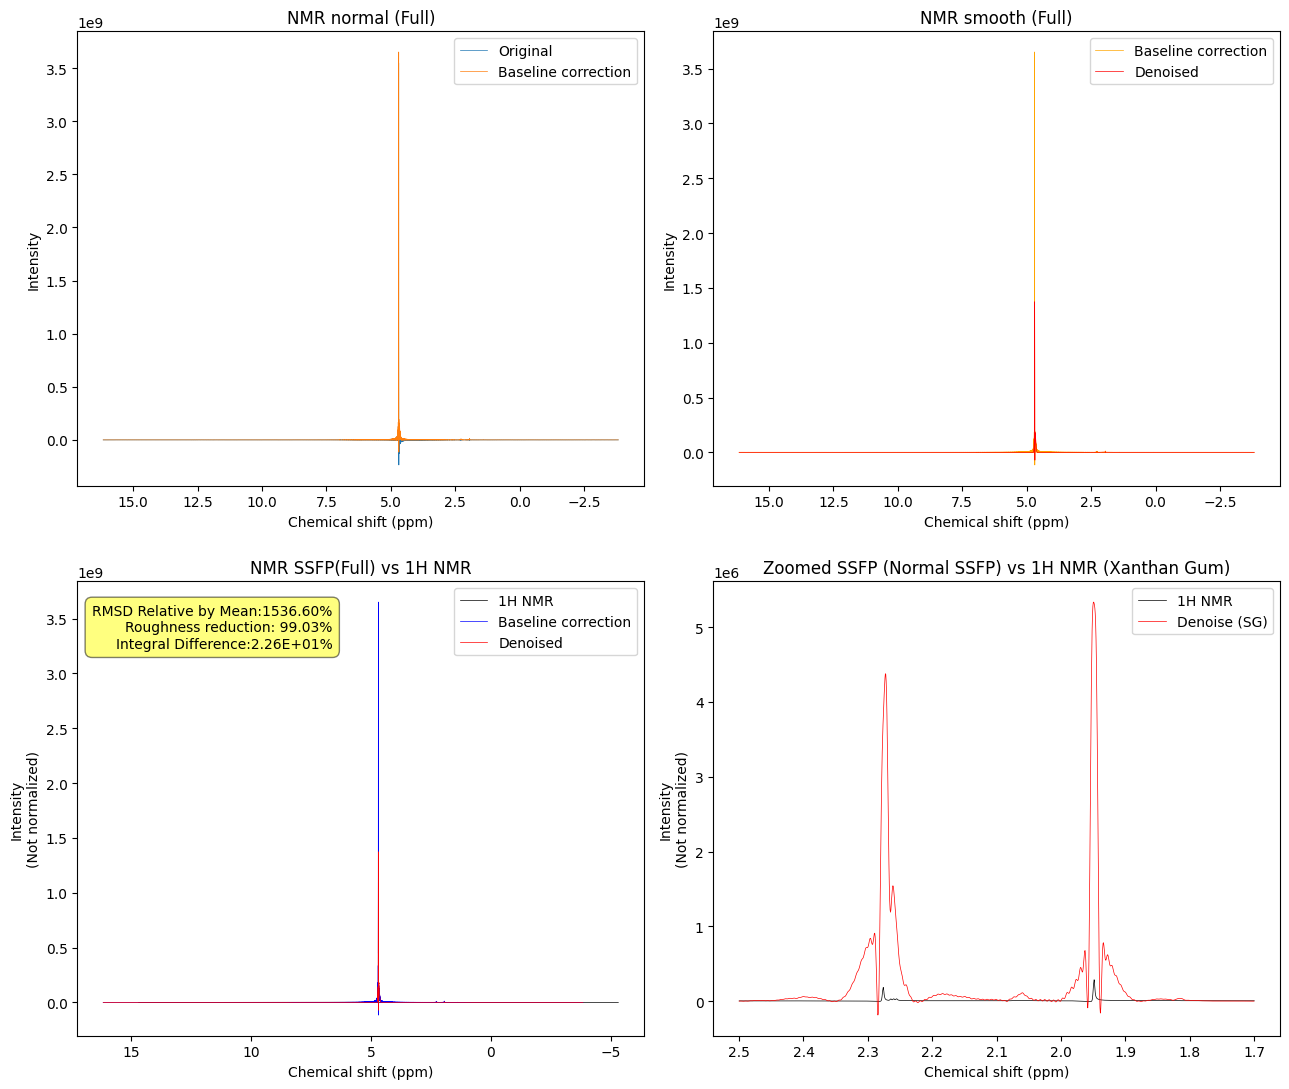



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  Max Equation
Original               1.073584e+04   1.153228e+04  1.011435e+04  6.158170e+03
Denoised               5.854972e+06   1.887875e+06  1.796781e+06  1.193641e+06


In [ ]:
smooth_function('Xanthan Gum','Normal SSFP','Seq1_XG_35°.csv','1H_XG.csv',4,0.06,2.5,1.7,(-0.26,-0.235),33,2,False)

###Sequence 2
###SSFPdx_n2

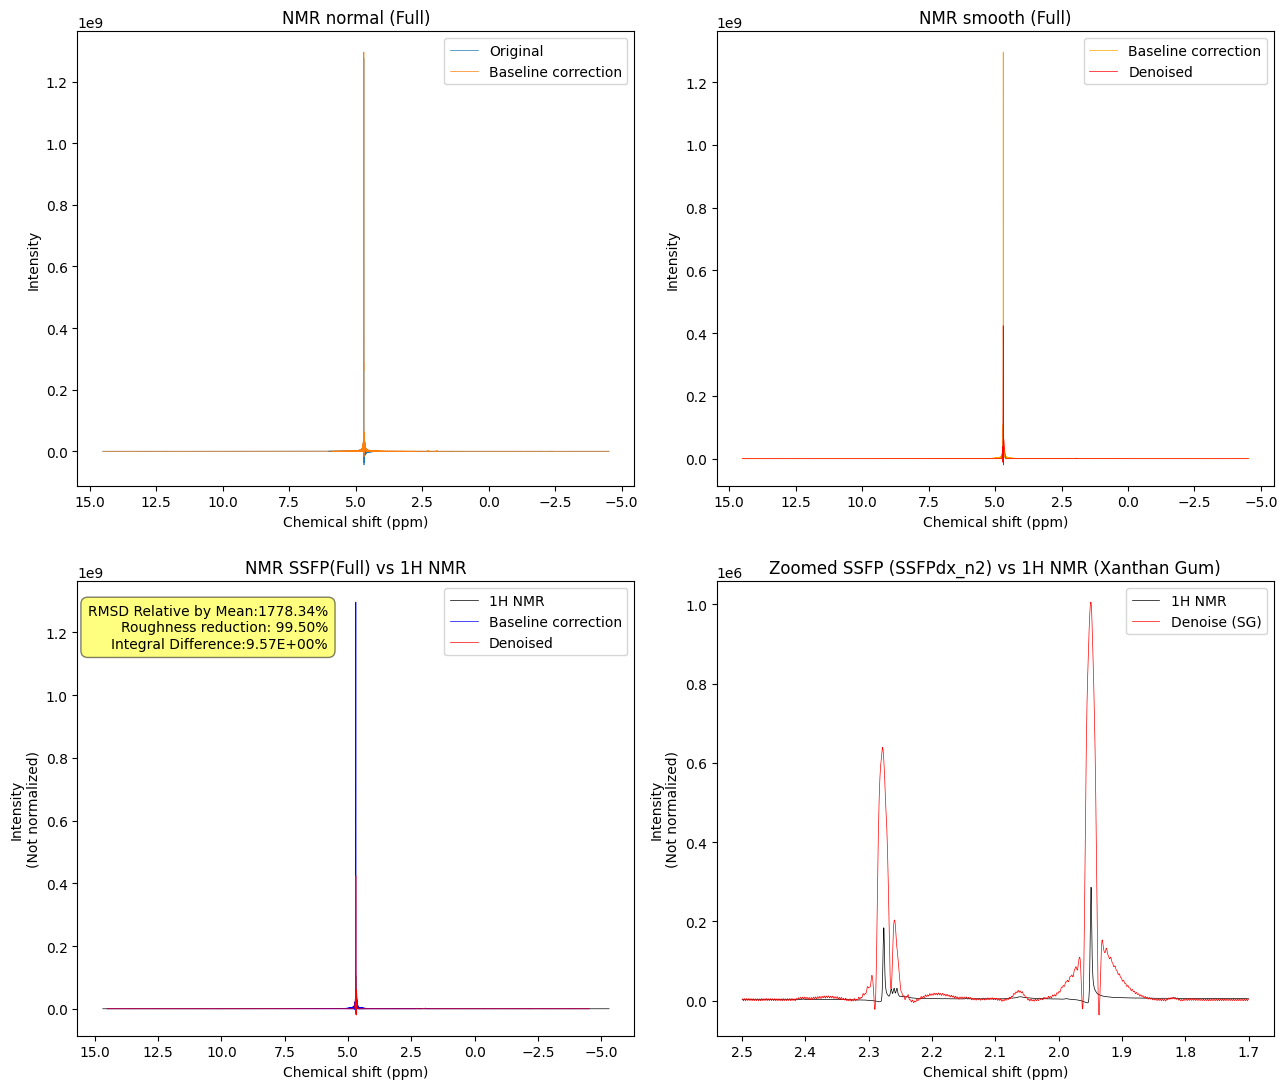



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               11796.962127   13030.160743   11746.044439   
Denoised              229899.340559  154431.714385  129044.608722   

          Max Equation  
Original   8029.055955  
Denoised  75592.244184  


In [ ]:
smooth_function('Xanthan Gum','SSFPdx_n2','Seq2_XG_20°.csv','1H_XG.csv',4,0.06,2.5,1.7,(-0.26,-0.235),47,3,False)

###Sequence 3
###SSFPdx_n4

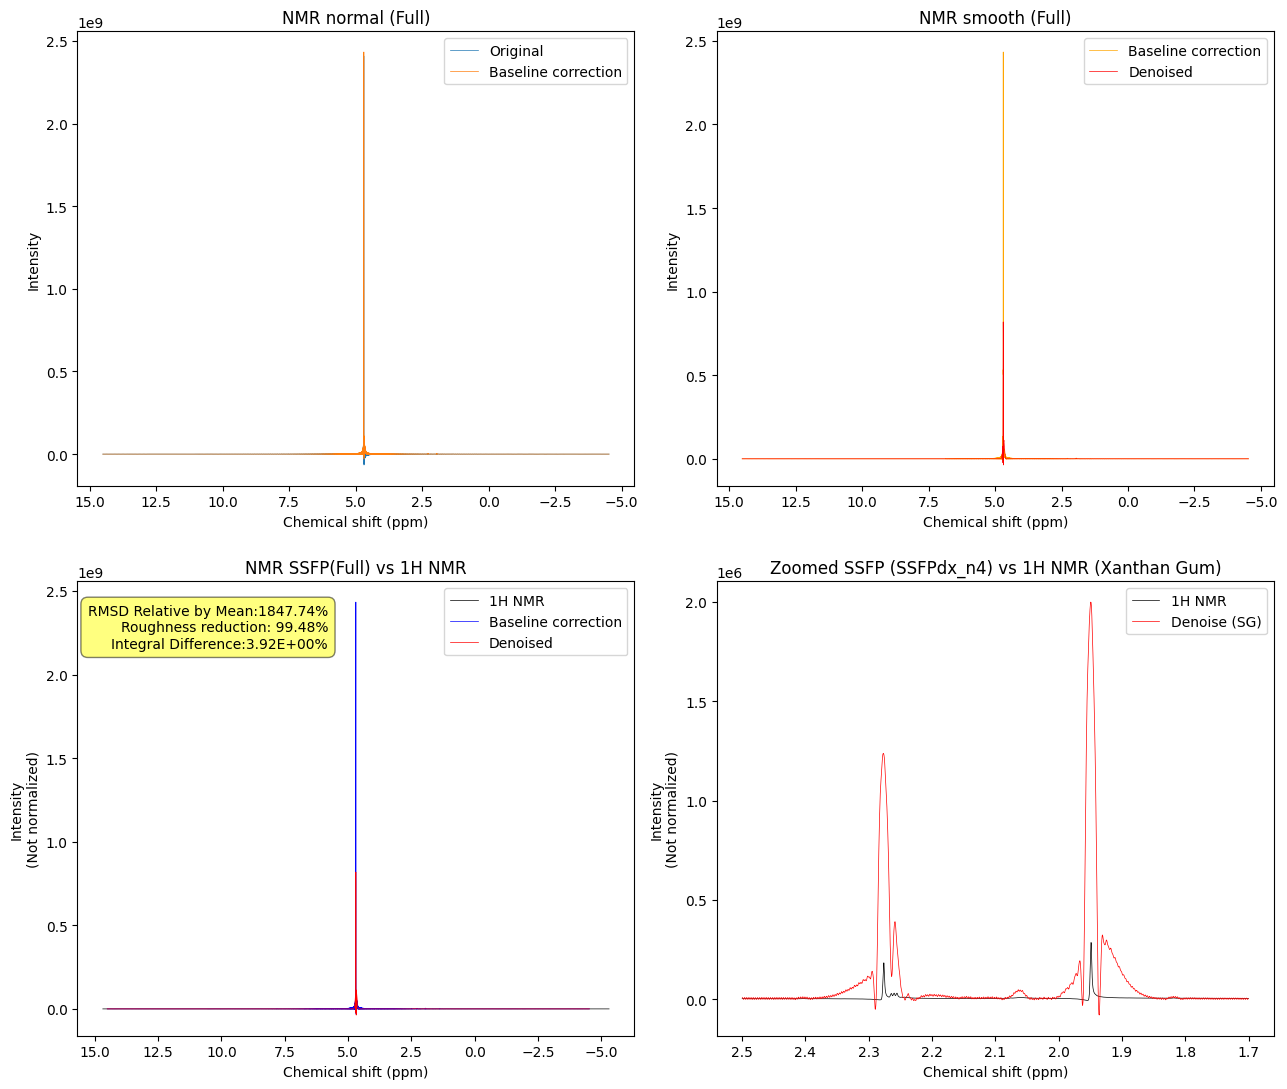



SNR Results
          NMR Manufactured Equation  Mean Equation   RMS Equation  \
Original               12301.659535   10612.174939    8629.669073   
Denoised              248941.847763  179526.657541  145988.010091   

          Max Equation  
Original   5162.029379  
Denoised  87764.205874  


In [ ]:
smooth_function('Xanthan Gum','SSFPdx_n4','Seq3_XG_20°.csv','1H_XG.csv',4,0.06,2.5,1.7,(-0.26,-0.235),47,3,False)

###Sequence 4
###SSFPdx_n8

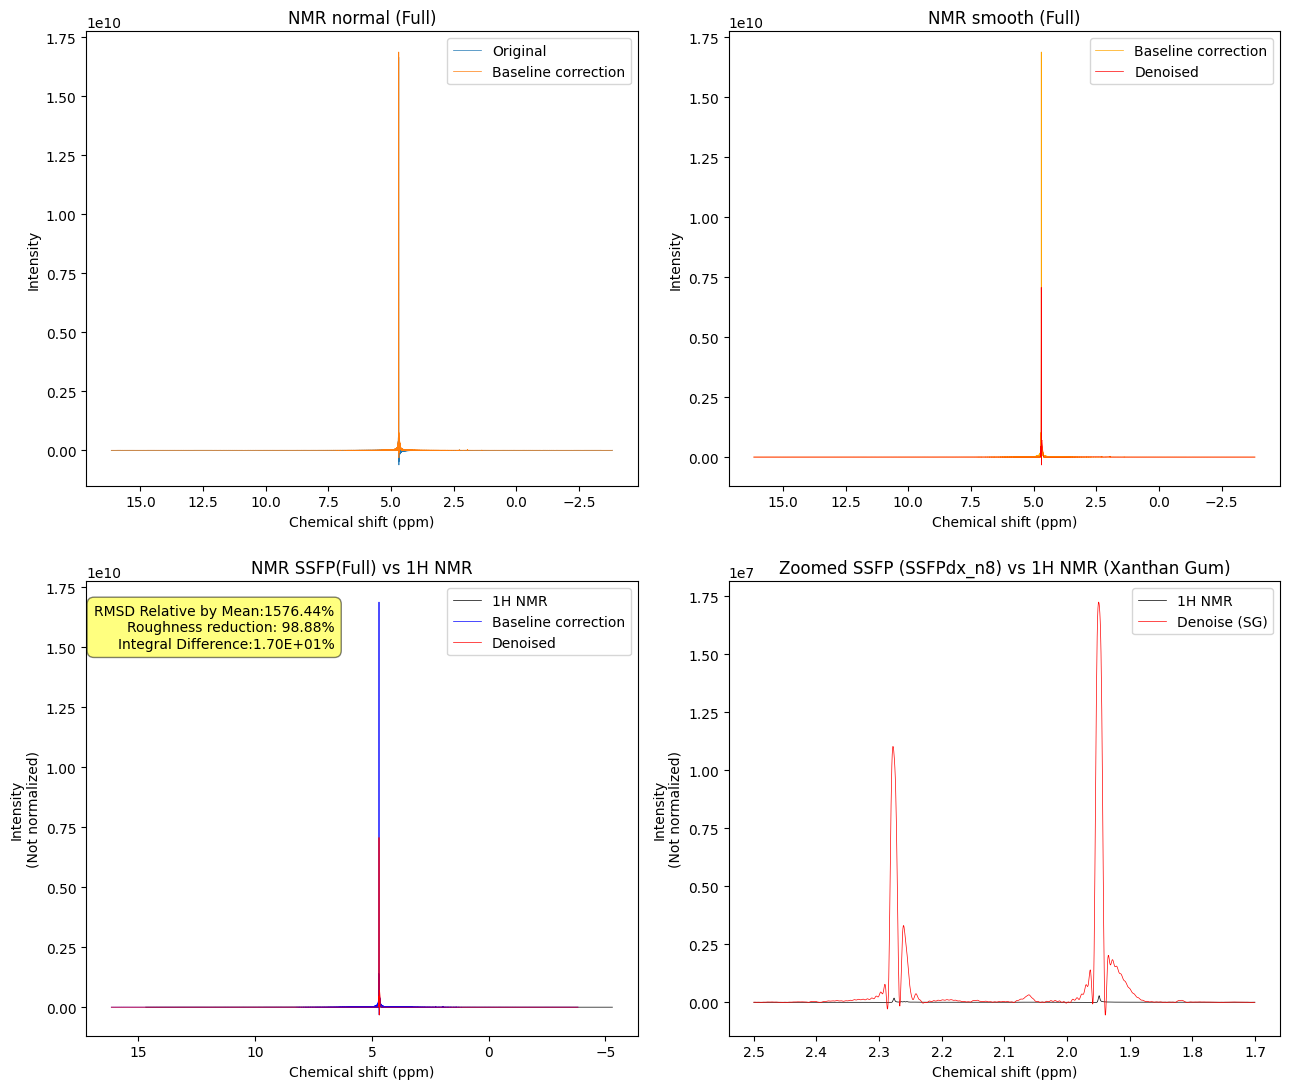



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  \
Original               1.249590e+04   8.117962e+03  6.807542e+03   
Denoised               3.151358e+06   1.945845e+06  1.678807e+06   

           Max Equation  
Original    4278.353535  
Denoised  965462.376911  


In [ ]:
smooth_function('Xanthan Gum','SSFPdx_n8','Seq4_XG_20°.csv','1H_XG.csv',4,0.06,2.5,1.7,(-0.26,-0.235),33,2,False)

###Sequence 5
###SSFPdxdt1024

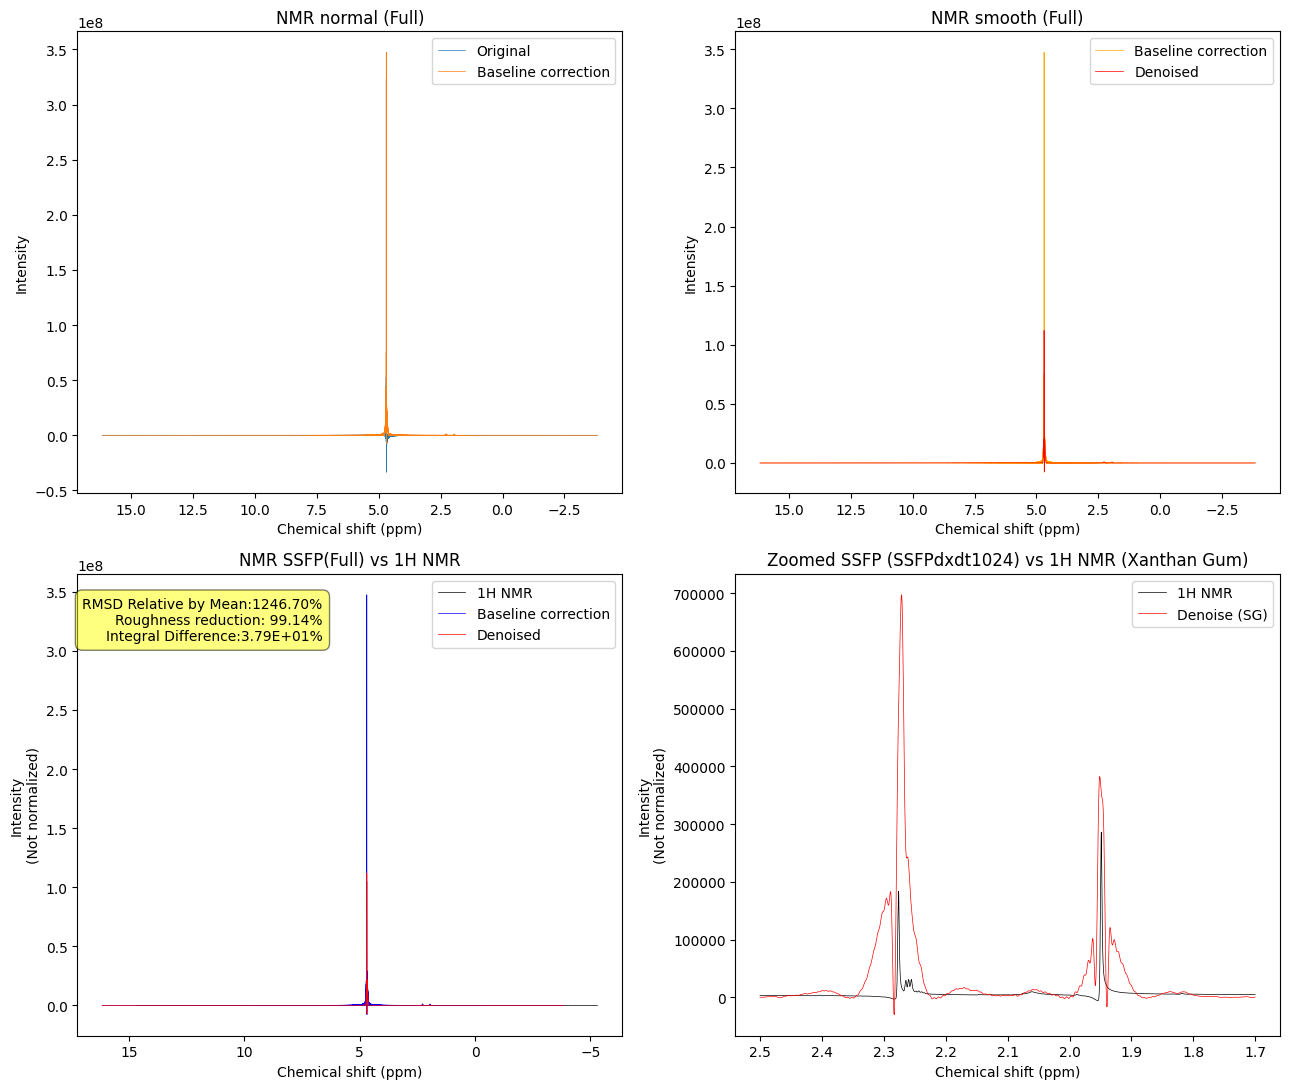



SNR Results
          NMR Manufactured Equation  Mean Equation  RMS Equation  Max Equation
Original                9005.868374    9907.095046   8928.690755   5911.254748
Denoised              111589.626049   70517.555919  59666.015874  34853.775290


In [ ]:
smooth_function('Xanthan Gum','SSFPdxdt1024','Seq5_XG_30°.csv','1H_XG.csv',4,0.06,2.5,1.7,(-0.26,-0.235),33,2,False)

##Sequence comparison

In [ ]:
#Setting Paths again:
path_ssfp_cholac_acid='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cholac_acid'
path_ssfp_cyclosporine='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cyclosporine'
path_ssfp_Ethylbenzene='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-EB'
path_ssfp_pamoic_acid='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Pamoic_acid'
path_ssfp_xanthan_gum='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-XG'

import os
import pandas as pd # Import pandas here if not already imported globally
import re

files_ssfp_cholac_acid=[f for f in os.listdir(path_ssfp_cholac_acid) if os.path.isfile(os.path.join(path_ssfp_cholac_acid, f))]
files_ssfp_cyclosporine=[f for f in os.listdir(path_ssfp_cyclosporine) if os.path.isfile(os.path.join(path_ssfp_cyclosporine, f))]
files_ssfp_Ethylbenzene=[f for f in os.listdir(path_ssfp_Ethylbenzene) if os.path.isfile(os.path.join(path_ssfp_Ethylbenzene, f))]
files_ssfp_pamoic_acid=[f for f in os.listdir(path_ssfp_pamoic_acid) if os.path.isfile(os.path.join(path_ssfp_pamoic_acid, f))]
files_ssfp_xanthan_gum=[f for f in os.listdir(path_ssfp_xanthan_gum) if os.path.isfile(os.path.join(path_ssfp_xanthan_gum, f))]

# Helper function to extract sequence number for sorting
def extract_seq_number(filename):
    match = re.search(r'Seq(\d+)_', filename)
    if match:
        return int(match.group(1))
    return float('inf') # Handles files not matching the pattern by putting them at the end

#Sort:
files_ssfp_cholac_acid.sort(key=extract_seq_number)
files_ssfp_cyclosporine.sort(key=extract_seq_number)
files_ssfp_Ethylbenzene.sort(key=extract_seq_number)
files_ssfp_pamoic_acid.sort(key=extract_seq_number)
files_ssfp_xanthan_gum.sort(key=extract_seq_number)


files_ssfp_molecules = pd.DataFrame({
    'Cholac acid': pd.Series(files_ssfp_cholac_acid),
    'Cyclosporine': pd.Series(files_ssfp_cyclosporine),
    'EB': pd.Series(files_ssfp_Ethylbenzene),
    'Pamoic acid': pd.Series(files_ssfp_pamoic_acid),
    'Xanthan Gum': pd.Series(files_ssfp_xanthan_gum)
})

display(files_ssfp_molecules)

,Cholac acid,Cyclosporine,EB,Pamoic acid,Xanthan Gum
0,Seq1_cholac_75°.csv,Seq1_cyclosporine_70°.csv,Seq1_EB_30°.csv,Seq1_pamoic acid_70°.csv,Seq1_XG_35°.csv
1,Seq2_cholac_70°.csv,Seq2_cyclosporine_70°.csv,Seq2_EB_40°.csv,Seq2_pamoic acid_60°.csv,Seq2_XG_20°.csv
2,Seq3_cholac_75°.csv,Seq3_cyclosporine_70°.csv,Seq3_EB_40°.csv,Seq3_pamoic acid_65°.csv,Seq3_XG_20°.csv
3,Seq4_cholac_70°.csv,Seq4_cyclosporine_70°.csv,Seq4_EB_35°.csv,Seq4_pamoic acid_65°.csv,Seq4_XG_20°.csv
4,Seq5_cholac_90°.csv,Seq5_cyclosporine_65°.csv,Seq5_EB_40°.csv,Seq5_pamoic acid_55°.csv,Seq5_XG_30°.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
from pybaselines import Baseline
from pybaselines.whittaker import arpls

def smooth_function_plotting(ax,molecule,sequence,input_filename,proton_filename,exponent_lambda,weight,upper_limit,lower_limit,noise_range,width_length,polyorder,Normalized, plot_color):
    path_proton='/content/SSFP---High-NMR/1H-spectrums'
    proton_filename=f'{path_proton}/{proton_filename}'

    if molecule=='Cholic acid':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cholac_acid'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Cyclosporine':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cyclosporine'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Ethylbenzene':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-EB'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Pamoic acid':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Pamoic_acid'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Xanthan Gum':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-XG'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None

    data = np.genfromtxt(input_filename, delimiter=',',
                        skip_footer=1, skip_header=1)
    data_proton = np.genfromtxt(proton_filename, delimiter=',',
                        skip_footer=1, skip_header=1)
    intensity_proton = data_proton[:, 0]
    chemical_shift_proton = data_proton[:, 2]

    # Existing data processing steps
    lambda_coef=10**exponent_lambda
    intensity_irregular = data[:, 0]
    chemical_shift = data[:, 2]
    fitter= Baseline(x_data=chemical_shift)
    baseline, params=fitter.iasls(intensity_irregular,lam=lambda_coef,p=weight)
    intensity= intensity_irregular-baseline
    smoothed_intensity_prev= savgol_filter(intensity, width_length,polyorder)
    fitter2=Baseline(x_data=chemical_shift)
    baseline2, params2=fitter2.iasls(smoothed_intensity_prev,lam=lambda_coef,p=weight)
    smoothed_intensity=smoothed_intensity_prev-baseline2

    # Metrics calculation (RMSD, Roughness, Integral Difference)
    differences=intensity-smoothed_intensity
    rmsd = np.sqrt(np.mean(differences**2))
    mean_intensity=np.mean(np.abs(intensity))
    rmsd_relative=(rmsd/mean_intensity)*100
    roughness_original=np.sum(np.diff(intensity, n=2)**2)
    roughness_smoothed=np.sum(np.diff(smoothed_intensity, n=2)**2)
    roughness_difference=((roughness_original-roughness_smoothed)/roughness_original)*100

    integral_original=np.abs(np.trapezoid(intensity,chemical_shift))
    integral_suavizada=np.abs(np.trapezoid(smoothed_intensity,chemical_shift))
    if integral_original != 0:
        diferencia_integral=(np.abs(integral_suavizada-integral_original)/integral_original)*100
    else:
        diferencia_integral='Can not be calculated'

    data_base_correct = pd.DataFrame({'Chemical Shift': chemical_shift, 'Intensity': intensity})
    data_smooth = pd.DataFrame({'Chemical Shift': chemical_shift, 'Intensity': smoothed_intensity})

    # Delimited range in Spectrum:
    mask = (chemical_shift <= upper_limit) & (chemical_shift >= lower_limit)
    original_data_extracted=data[mask]
    intensity_original_extracted=original_data_extracted[:,0]
    chemical_shift_original_ex=original_data_extracted[:,2]
    extracted_data_df = data_smooth[mask]
    chemical_shift_extracted = extracted_data_df['Chemical Shift'].values
    intensity_extracted = extracted_data_df['Intensity'].values
    smoothed_intensity_extracted = savgol_filter(intensity_extracted, width_length,polyorder)

    #For Proton:
    mask_proton = (chemical_shift_proton <= upper_limit) & (chemical_shift_proton >= lower_limit)
    data_proton_extracted=data_proton[mask_proton]
    intensity_proton_extracted=data_proton_extracted[:,0]
    chemical_shift_proton_extracted=data_proton_extracted[:,2]

    if Normalized == True:
     intensity_proton_norm=intensity_proton/np.max(intensity_proton)
     intensity_proton_extracted_norm=intensity_proton_extracted/np.max(intensity_proton_extracted)
     intensity_norm=intensity/np.max(intensity)
     smoothed_intensity_norm=smoothed_intensity/np.max(smoothed_intensity)
     intensity_extracted_norm=intensity_extracted/np.max(intensity_extracted)
     smoothed_intensity_extracted_norm=smoothed_intensity_extracted/np.max(smoothed_intensity_extracted)
     mention= f'(Normalized)'

    else:
     intensity_proton_norm=intensity_proton
     intensity_proton_extracted_norm=intensity_proton_extracted
     intensity_norm=intensity
     smoothed_intensity_norm=smoothed_intensity
     intensity_extracted_norm=intensity_extracted
     smoothed_intensity_extracted_norm=smoothed_intensity_extracted
     mention= f'(Not normalized)'

    #Generating plottings:
    ax.plot(chemical_shift_extracted,smoothed_intensity_extracted_norm,lw=0.5,label=sequence, color=plot_color)
    ax.invert_xaxis()

    return chemical_shift_proton_extracted, intensity_proton_extracted_norm

###For Cholic acid

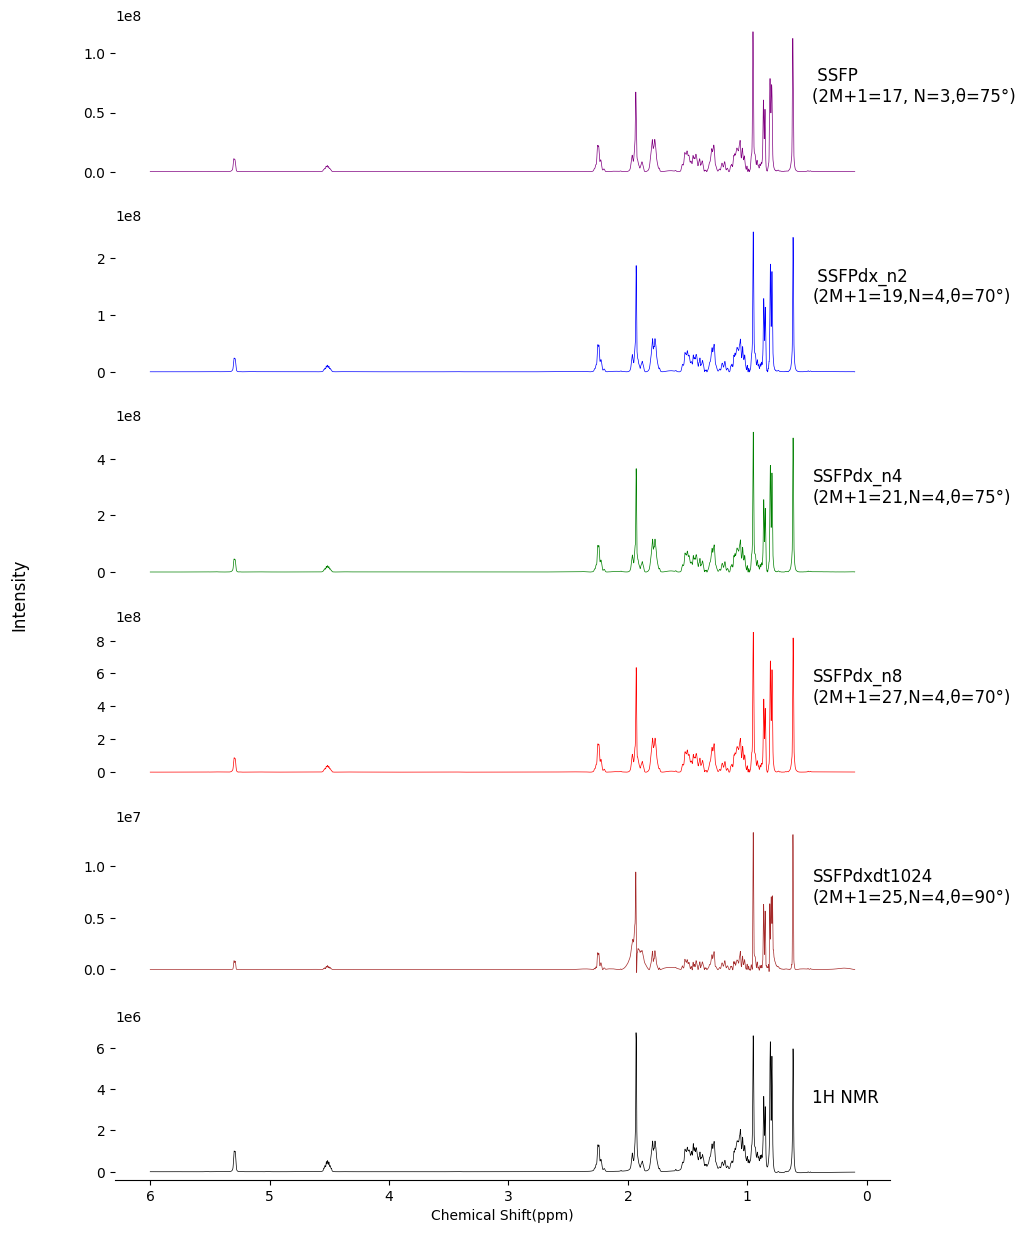

In [ ]:
Norm=False #Normalization setting

#Chemical shift range for spectra comparison
maximum_limit=6.0
min_limit=0.1

#Plotting:
fig, (ax0,ax1,ax2,ax3,ax4,ax5)=plt.subplots(6,1,figsize=(10,15))
proton_shift,proton_int=smooth_function_plotting(ax0,'Cholic acid','Normal SSFP','Seq1_cholac_75°.csv','1H_cholac.csv',5,0.01,maximum_limit,min_limit,(10.0, 15.0),17,3,Normalized=Norm, plot_color='purple')
smooth_function_plotting(ax1,'Cholic acid','SSFPdx_n2','Seq2_cholac_70°.csv','1H_cholac.csv',5,0.01,maximum_limit,min_limit,(10.0,14.0),19,4,Normalized=Norm, plot_color='blue')
smooth_function_plotting(ax2,'Cholic acid','SSFPdx_n4','Seq3_cholac_75°.csv','1H_cholac.csv',5,0.01,maximum_limit,min_limit,(9.0,14.0),21,4,Normalized=Norm, plot_color='green')
smooth_function_plotting(ax3,'Cholic acid','SSFPdx_n8','Seq4_cholac_70°.csv','1H_cholac.csv',5,0.01,maximum_limit,min_limit,(10.0,15.0),27,4,Normalized=Norm, plot_color='red')
smooth_function_plotting(ax4,'Cholic acid','SSFPdxdt1024','Seq5_cholac_90°.csv','1H_cholac.csv',5,0.05,maximum_limit,min_limit,(10.0,15.0),25,4,Normalized=Norm, plot_color='brown')

ax5.plot(proton_shift,proton_int,lw=0.5, color='black')
ax5.invert_xaxis()

Labels=[' SSFP\n(2M+1=17, N=3,θ=75°)',' SSFPdx_n2\n(2M+1=19,N=4,θ=70°)','SSFPdx_n4\n(2M+1=21,N=4,θ=75°)','SSFPdx_n8\n(2M+1=27,N=4,θ=70°)','SSFPdxdt1024\n(2M+1=25,N=4,θ=90°)','1H NMR']
for i, ax in enumerate([ax0,ax1,ax2,ax3,ax4,ax5]):
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.text(0.9,0.5,Labels[i],transform=ax.transAxes,fontsize=12)
for ax in [ax0,ax1,ax2,ax3,ax4]:
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.set_xticks([])

plt.xlabel('Chemical Shift(ppm)')
plt.subplots_adjust(wspace=0,hspace=0.3)
if Norm==True:
  fig.supylabel('Intensity (Normalized)')
else:
  fig.supylabel('Intensity')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.show()

###For Cyclosporine

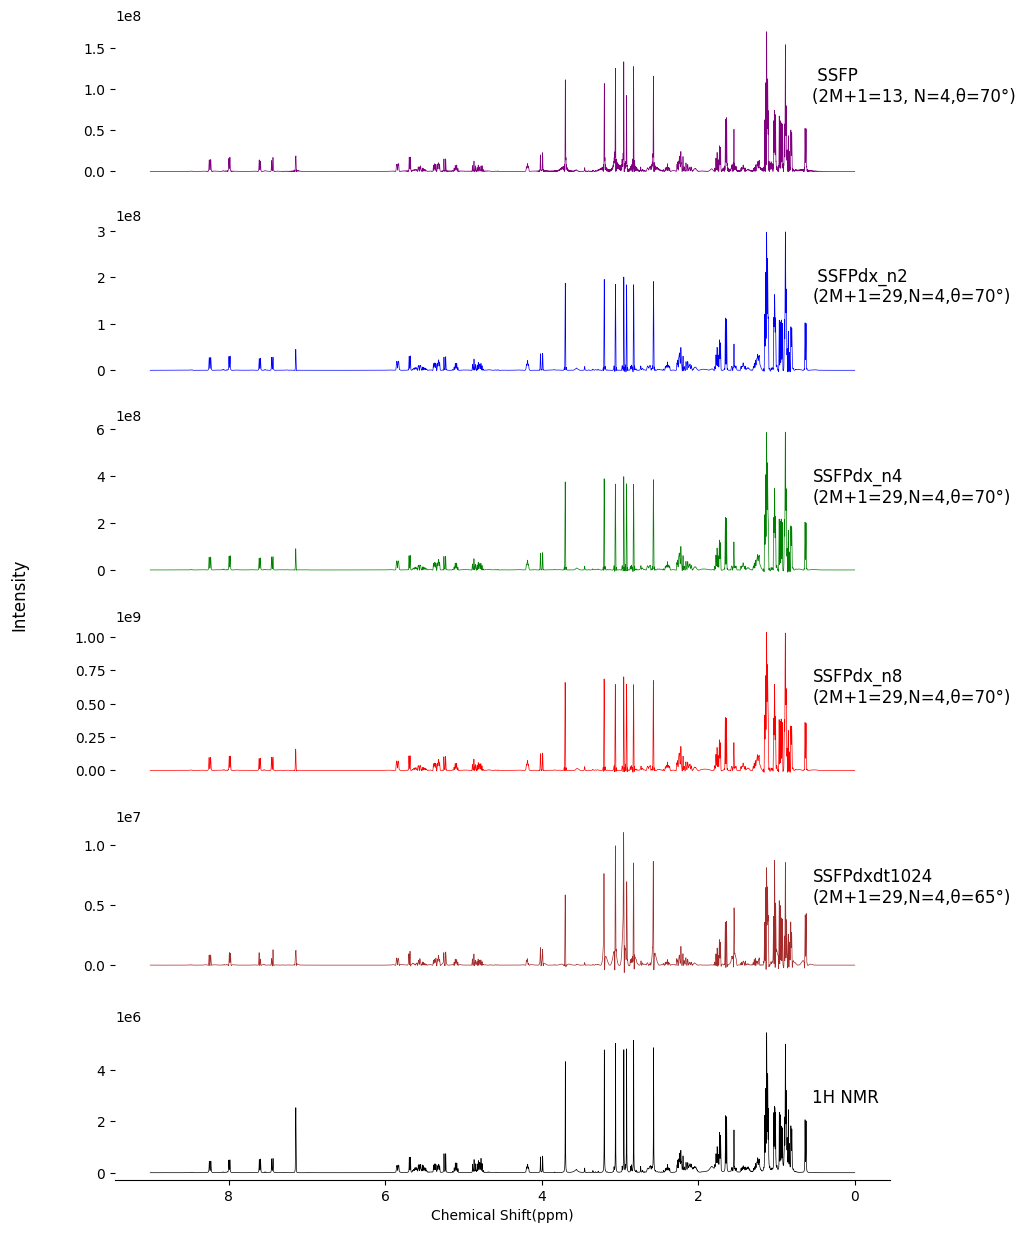

In [ ]:
Norm=False #Normalization setting

#Chemical Shift range for spectra comparison
maximum_limit=9
min_limit=0

#Plotting:

fig, (ax0,ax1,ax2,ax3,ax4,ax5)=plt.subplots(6,1,figsize=(10,15))
proton_shift,proton_int=smooth_function_plotting(ax0,'Cyclosporine','Normal SSFP','Seq1_cyclosporine_70°.csv','1H_cyclosporine.csv',3,0.01,maximum_limit,min_limit,(8.37,16.0),13,4,Normalized=Norm,plot_color='purple')
smooth_function_plotting(ax1,'Cyclosporine','SSFPdx_n2','Seq2_cyclosporine_70°.csv','1H_cyclosporine.csv',5,0.04,maximum_limit,min_limit,(8.37,14.49),29,4,Normalized=Norm, plot_color='blue')
smooth_function_plotting(ax2,'Cyclosporine','SSFPdx_n4','Seq3_cyclosporine_70°.csv','1H_cyclosporine.csv',5,0.05,maximum_limit,min_limit,(8.37,14.49),29,4,Normalized=Norm, plot_color='green')
smooth_function_plotting(ax3,'Cyclosporine','SSFPdx_n8','Seq4_cyclosporine_70°.csv','1H_cyclosporine.csv',5,0.05,maximum_limit,min_limit,(8.37,16.0),29,4,Normalized=Norm, plot_color='red')
smooth_function_plotting(ax4,'Cyclosporine','SSFPdxdt1024','Seq5_cyclosporine_65°.csv','1H_cyclosporine.csv',4,0.09,maximum_limit,min_limit,(8.37,16.0),29,4,Normalized=Norm, plot_color='brown')

ax5.plot(proton_shift,proton_int,lw=0.5, color='black')
ax5.invert_xaxis()

Labels=[' SSFP\n(2M+1=13, N=4,θ=70°)',' SSFPdx_n2\n(2M+1=29,N=4,θ=70°)','SSFPdx_n4\n(2M+1=29,N=4,θ=70°)','SSFPdx_n8\n(2M+1=29,N=4,θ=70°)','SSFPdxdt1024\n(2M+1=29,N=4,θ=65°)','1H NMR']
for i, ax in enumerate([ax0,ax1,ax2,ax3,ax4,ax5]):
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.text(0.9,0.5,Labels[i],transform=ax.transAxes,fontsize=12)
for ax in [ax0,ax1,ax2,ax3,ax4]:
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.set_xticks([])

plt.xlabel('Chemical Shift(ppm)')
plt.subplots_adjust(wspace=0,hspace=0.3)
if Norm==True:
  fig.supylabel('Intensity (Normalized)')
else:
  fig.supylabel('Intensity')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.show()

###For Ethylbenzene (EB)

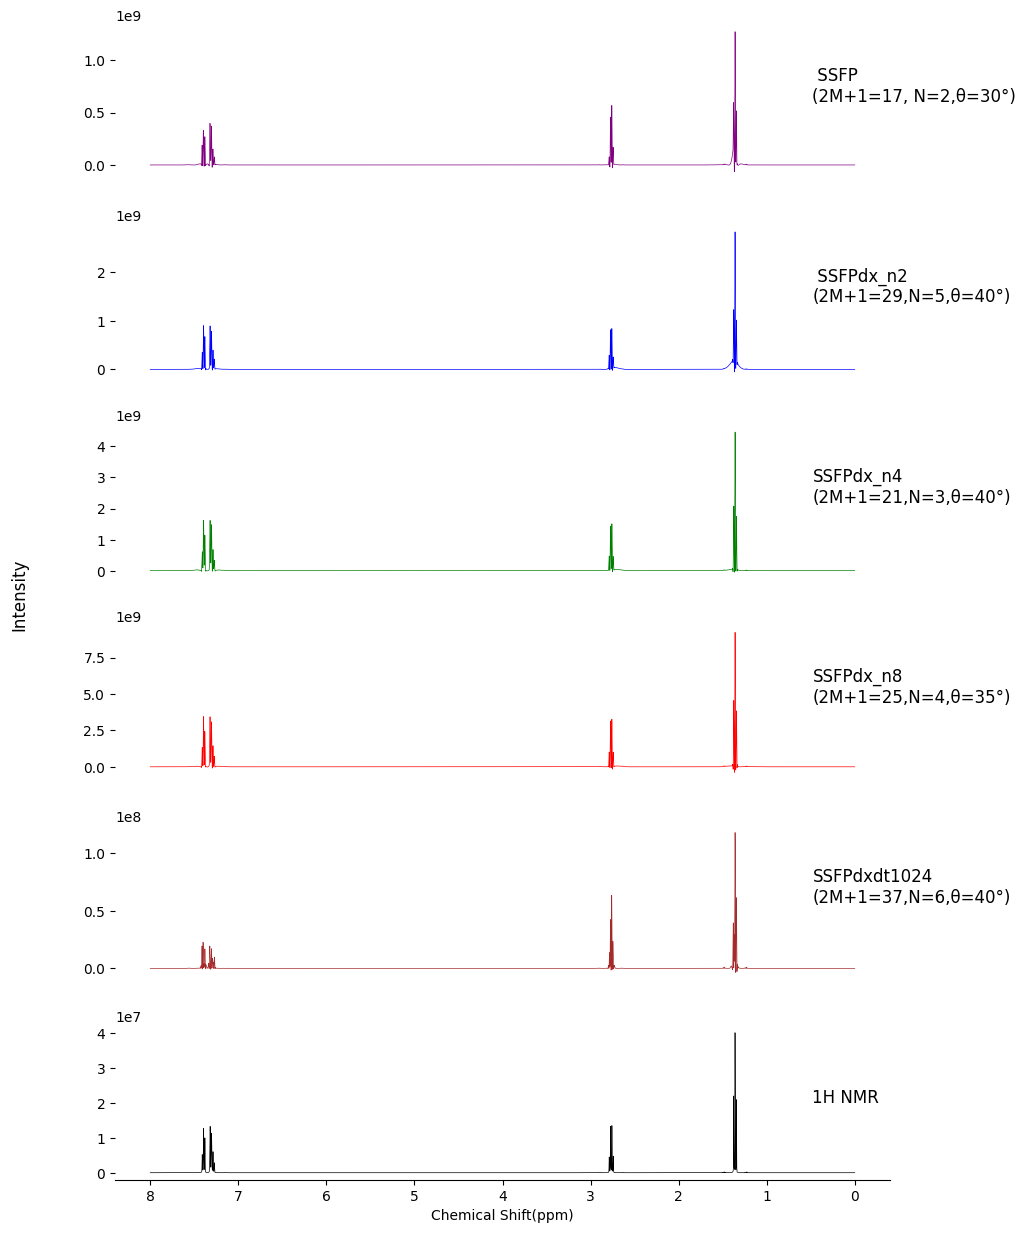

In [ ]:
Norm=False #Normalization setting

#Chemical shift range for spectra comparison
maximum_limit=8
min_limit=0

#Plotting:
fig, (ax0,ax1,ax2,ax3,ax4,ax5)=plt.subplots(6,1,figsize=(10,15))
proton_shift,proton_int=smooth_function_plotting(ax0,'Ethylbenzene','Normal SSFP','Seq1_EB_30°.csv','1H_EB.csv',4,0.09,maximum_limit,min_limit,(8.00,14.30),17,2,Normalized=Norm,plot_color='purple')
smooth_function_plotting(ax1,'Ethylbenzene','SSFPdx_n2','Seq2_EB_40°.csv','1H_EB.csv',4,0.02,maximum_limit,min_limit,(8.00,14.30),29,5,Normalized=Norm, plot_color='blue')
smooth_function_plotting(ax2,'Ethylbenzene','SSFPdx_n4','Seq3_EB_40°.csv','1H_EB.csv',5,0.05,maximum_limit,min_limit,(8.00,14.30),21,3,Normalized=Norm, plot_color='green')
smooth_function_plotting(ax3,'Ethylbenzene','SSFPdx_n8','Seq4_EB_35°.csv','1H_EB.csv',5,0.05,maximum_limit,min_limit,(8.00,14.30),25,4,Normalized=Norm, plot_color='red')
smooth_function_plotting(ax4,'Ethylbenzene','SSFPdxdt1024','Seq5_EB_40°.csv','1H_EB.csv',2,0.1,maximum_limit,min_limit,(8.00,14.30),37,6,Normalized=Norm, plot_color='brown')

ax5.plot(proton_shift,proton_int,lw=0.5, color='black')
ax5.invert_xaxis()

Labels=[' SSFP\n(2M+1=17, N=2,θ=30°)',' SSFPdx_n2\n(2M+1=29,N=5,θ=40°)','SSFPdx_n4\n(2M+1=21,N=3,θ=40°)','SSFPdx_n8\n(2M+1=25,N=4,θ=35°)','SSFPdxdt1024\n(2M+1=37,N=6,θ=40°)','1H NMR']
for i, ax in enumerate([ax0,ax1,ax2,ax3,ax4,ax5]):
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.text(0.9,0.5,Labels[i],transform=ax.transAxes,fontsize=12)
for ax in [ax0,ax1,ax2,ax3,ax4]:
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.set_xticks([])

plt.xlabel('Chemical Shift(ppm)')
plt.subplots_adjust(wspace=0,hspace=0.3)
if Norm==True:
  fig.supylabel('Intensity (Normalized)')
else:
  fig.supylabel('Intensity')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.show()

###For Pamoic acid

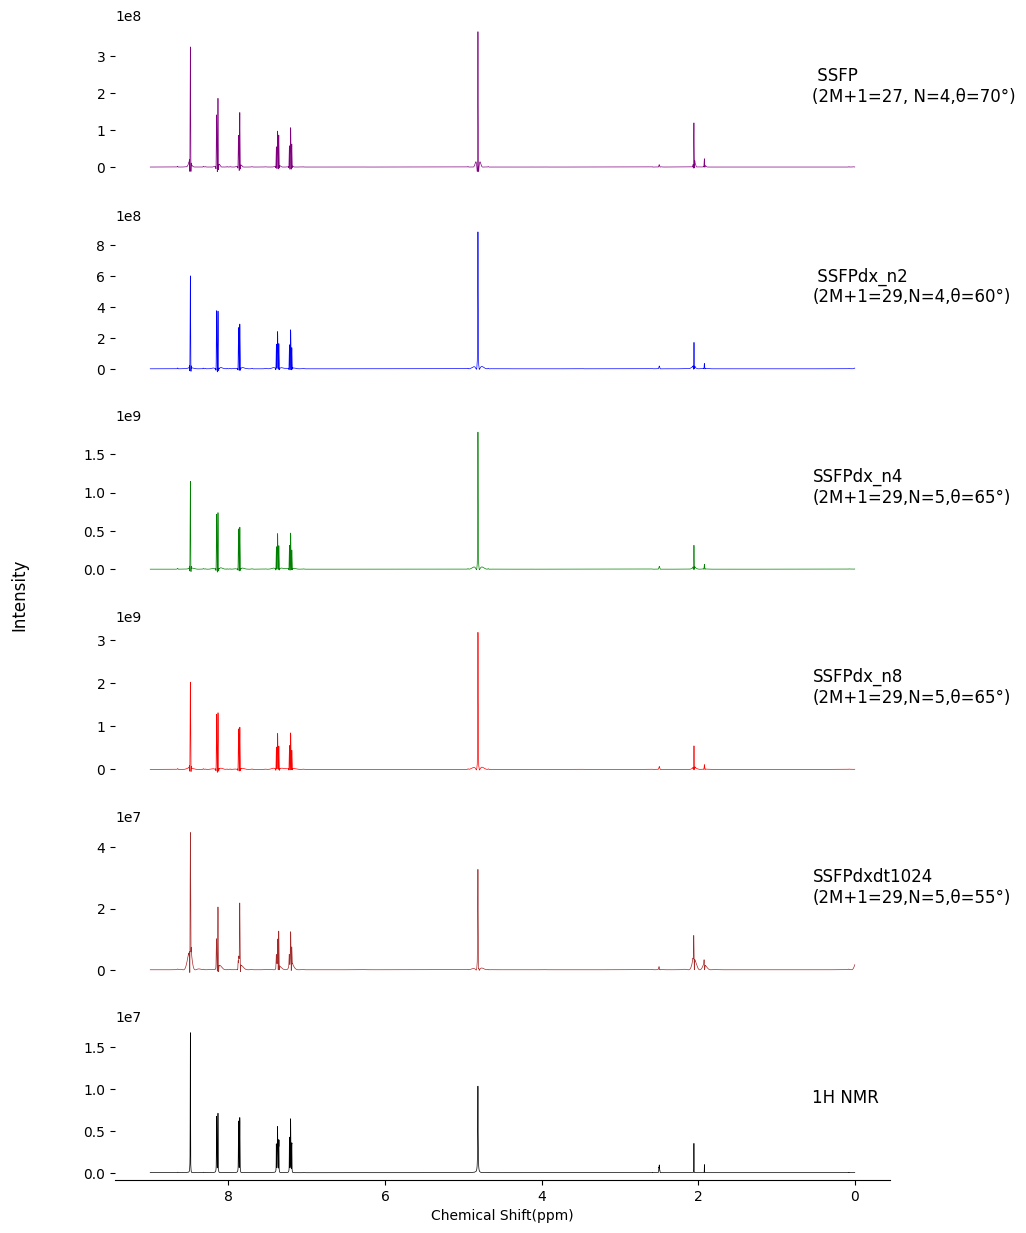

In [ ]:
Norm=False #Normalization setting

#Chemical shift range for spectra comparison
maximum_limit=9
min_limit=0

#Plotting:
fig, (ax0,ax1,ax2,ax3,ax4,ax5)=plt.subplots(6,1,figsize=(10,15))
proton_shift,proton_int=smooth_function_plotting(ax0,'Pamoic acid','Normal SSFP','Seq1_pamoic acid_70°.csv','1H-pamoic _acid.csv',3,0.102,maximum_limit,min_limit,(-0.6,-0.5),27,4,Normalized=Norm,plot_color='purple')
smooth_function_plotting(ax1,'Pamoic acid','SSFPdx_n2',"Seq2_pamoic acid_60°.csv","1H-pamoic _acid.csv",4,0.06,maximum_limit,min_limit,(-0.6,-0.5),29,4,Normalized=Norm, plot_color='blue')
smooth_function_plotting(ax2,'Pamoic acid','SSFPdx_n4','Seq3_pamoic acid_65°.csv','1H-pamoic _acid.csv',4,0.06,maximum_limit,min_limit,(-0.6,-0.5),29,5,Normalized=Norm, plot_color='green')
smooth_function_plotting(ax3,'Pamoic acid','SSFPdx_n8','Seq4_pamoic acid_65°.csv','1H-pamoic _acid.csv',4,0.06,maximum_limit,min_limit,(-0.6,-0.5),29,5,Normalized=Norm, plot_color='red')
smooth_function_plotting(ax4,'Pamoic acid','SSFPdxdt1024','Seq5_pamoic acid_55°.csv','1H-pamoic _acid.csv',4,0.06,maximum_limit,min_limit,(-0.6,-0.5),29,5,Normalized=Norm, plot_color='brown')

ax5.plot(proton_shift,proton_int,lw=0.5, color='black')
ax5.invert_xaxis()

Labels=[' SSFP\n(2M+1=27, N=4,θ=70°)',' SSFPdx_n2\n(2M+1=29,N=4,θ=60°)','SSFPdx_n4\n(2M+1=29,N=5,θ=65°)','SSFPdx_n8\n(2M+1=29,N=5,θ=65°)','SSFPdxdt1024\n(2M+1=29,N=5,θ=55°)','1H NMR']
for i, ax in enumerate([ax0,ax1,ax2,ax3,ax4,ax5]):
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.text(0.9,0.5,Labels[i],transform=ax.transAxes,fontsize=12)
for ax in [ax0,ax1,ax2,ax3,ax4]:
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.set_xticks([])

plt.xlabel('Chemical Shift(ppm)')
plt.subplots_adjust(wspace=0,hspace=0.3)
if Norm==True:
  fig.supylabel('Intensity (Normalized)')
else:
  fig.supylabel('Intensity')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.show()

###For Xanthan Gum (XG)

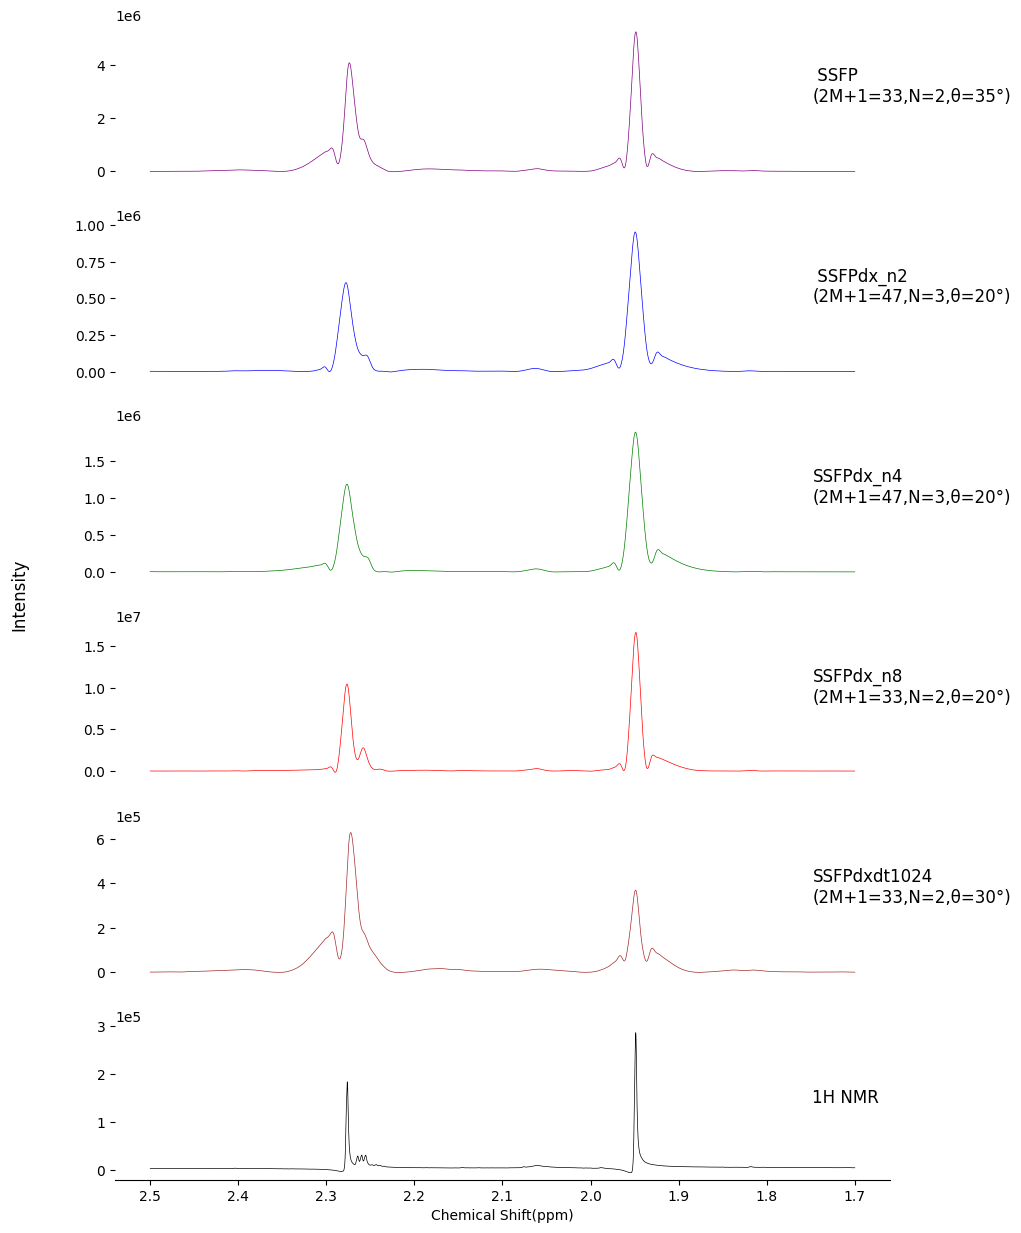

In [ ]:
Norm=False #Normalization setting

#Chemical shift range for spectra comparison:
maximum_limit=2.5
min_limit=1.7

#Plotting:
fig, (ax0,ax1,ax2,ax3,ax4,ax5)=plt.subplots(6,1,figsize=(10,15))
proton_shift,proton_int=smooth_function_plotting(ax0,'Xanthan Gum','Normal SSFP','Seq1_XG_35°.csv','1H_XG.csv',4,0.06,maximum_limit,min_limit,(-0.26,-0.235),33,2,Normalized=Norm,plot_color='purple')
smooth_function_plotting(ax1,'Xanthan Gum','SSFPdx_n2','Seq2_XG_20°.csv','1H_XG.csv',4,0.06,maximum_limit,min_limit,(-0.26,-0.235),47,3,Normalized=Norm, plot_color='blue')
smooth_function_plotting(ax2,'Xanthan Gum','SSFPdx_n4','Seq3_XG_20°.csv','1H_XG.csv',4,0.06,maximum_limit,min_limit,(-0.26,-0.235),47,3,Normalized=Norm, plot_color='green')
smooth_function_plotting(ax3,'Xanthan Gum','SSFPdx_n8','Seq4_XG_20°.csv','1H_XG.csv',4,0.06,maximum_limit,min_limit,(-0.26,-0.235),33,2,Normalized=Norm, plot_color='red')
smooth_function_plotting(ax4,'Xanthan Gum','SSFPdxdt1024','Seq5_XG_30°.csv','1H_XG.csv',4,0.06,maximum_limit,min_limit,(-0.26,-0.235),33,2,Normalized=Norm, plot_color='brown')

ax5.plot(proton_shift,proton_int,lw=0.5, color='black')
ax5.invert_xaxis()

Labels=[' SSFP\n(2M+1=33,N=2,θ=35°)',' SSFPdx_n2\n(2M+1=47,N=3,θ=20°)','SSFPdx_n4\n(2M+1=47,N=3,θ=20°)','SSFPdx_n8\n(2M+1=33,N=2,θ=20°)','SSFPdxdt1024\n(2M+1=33,N=2,θ=30°)','1H NMR']
for i, ax in enumerate([ax0,ax1,ax2,ax3,ax4,ax5]):
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.text(0.9,0.5,Labels[i],transform=ax.transAxes,fontsize=12)
  ax.ticklabel_format(axis='y',style='sci',scilimits=(0,0))

for ax in [ax0,ax1,ax2,ax3,ax4]:
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.spines['left'].set_visible(False)
  ax.spines['bottom'].set_visible(False)
  ax.set_xticks([])

plt.xlabel('Chemical Shift(ppm)')
plt.subplots_adjust(wspace=0,hspace=0.3)
if Norm==True:
  fig.supylabel('Intensity (Normalized)')
else:
  fig.supylabel('Intensity')
plt.show()

##SNR comparison

In [3]:
def snr_data(molecule,sequence,input_filename,exponent_lambda,weight,upper_limit,lower_limit,noise_range,width_length,polyorder):

    if molecule=='Cholic acid':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cholac_acid'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Cyclosporine':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Cyclosporine'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Ethylbenzene':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-EB'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Pamoic acid':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-Pamoic_acid'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None
    if molecule=='Xanthan Gum':
     path_ssfp='/content/SSFP---High-NMR/SSFP-Spectrums-High_frequency/SSFP-XG'
     input_filename=f'{path_ssfp}/{input_filename}'
    else: None

    data = np.genfromtxt(input_filename, delimiter=',',
                        skip_footer=1, skip_header=1)

    # Existing data processing steps
    lambda_coef=10**exponent_lambda
    intensity_irregular = data[:, 0]
    chemical_shift = data[:, 2]
    fitter= Baseline(x_data=chemical_shift)
    baseline, params=fitter.iasls(intensity_irregular,lam=lambda_coef,p=weight)
    intensity= intensity_irregular-baseline
    smoothed_intensity_prev= savgol_filter(intensity, width_length,polyorder)
    fitter2= Baseline(x_data=chemical_shift)
    baseline2, params2=fitter2.iasls(smoothed_intensity_prev,lam=lambda_coef,p=weight)
    smoothed_intensity= smoothed_intensity_prev-baseline2

    # SNR Calculation for comparison
    cs_noise_min, cs_noise_max = noise_range
    noise_mask = (chemical_shift >= cs_noise_min) & (chemical_shift <= cs_noise_max)

    # 1. SNR - Original (Raw Data)
    noise_data_raw = intensity_irregular[noise_mask]
    signal_raw = np.max(np.abs(intensity_irregular)) # Signal from full raw spectrum

    noise_estimate_raw = calculate_nmr_manufactured_noise(noise_data_raw)
    snr_raw = signal_raw/(2*noise_estimate_raw)
    snr_metric_raw = f'SNR Raw: {snr_raw:.4f}\n'

    # 2. SNR - After Baseline Correction (Before Denoising)
    noise_data_baseline_corrected = intensity[noise_mask]
    signal_baseline_corrected = np.max(np.abs(intensity)) # Signal from full baseline-corrected spectrum

    noise_estimate_baseline_corrected = calculate_nmr_manufactured_noise(noise_data_baseline_corrected)
    snr_baseline_corrected = signal_baseline_corrected/(noise_estimate_baseline_corrected*2)
    snr_metric_baseline_corrected = f'SNR Baseline-Corrected: {snr_baseline_corrected:.4f}\n'

    # 3. SNR - After Denoising (NMR Manufactured Equation)
    noise_data_smoothed = smoothed_intensity[noise_mask]
    signal_smoothed = np.max(np.abs(smoothed_intensity)) # Signal from full smoothed spectrum

    noise_estimate_smoothed = calculate_nmr_manufactured_noise(noise_data_smoothed)
    snr_smoothed = signal_smoothed/(noise_estimate_smoothed*2)
    snr_metric_smoothed = f'SNR NMR Manufactured Equation Smoothed: {snr_smoothed:.4f}\n'

    #4. SNR - Before Mean
    noise_data_mean = intensity_irregular[noise_mask]
    snr_mean_raw = (signal_raw)/(calculate_noise_mean(noise_data_mean)*2)
    snr_metric_mean_raw = f'SNR Mean Raw: {snr_mean_raw:.4f}\n'

    #5 SNR - After Denoising - Mean
    noise_data_mean_corrected = smoothed_intensity[noise_mask]
    snr_mean_corrected = (signal_smoothed)/(calculate_noise_mean(noise_data_mean_corrected)*2)
    snr_metric_mean_corrected = f'SNR Mean Smoothed: {snr_mean_corrected:.4f}\n'

    #6. SNR - Before RMS
    noise_data_rms = intensity_irregular[noise_mask]
    snr_rms_raw = (signal_raw)/(calculate_noise_rms(noise_data_rms)*2)
    snr_metric_rms_raw = f'SNR RMS Raw: {snr_rms_raw:.4f}\n'

    #7 SNR - After Denoising - RMS
    noise_data_rms_corrected = smoothed_intensity[noise_mask]
    snr_rms_corrected = (signal_smoothed)/(calculate_noise_rms(noise_data_rms_corrected)*2)
    snr_metric_rms_corrected = f'SNR RMS Smoothed: {snr_rms_corrected:.4f}\n'

    #8. SNR - Before Max
    noise_data_max = intensity_irregular[noise_mask]
    snr_max_raw = (signal_raw)/(calculate_noise_max(noise_data_max)*2)
    snr_metric_max_raw = f'SNR Max Raw: {snr_max_raw:.4f}\n'

    #9 SNR - After Denoising - Max
    noise_data_max_corrected = smoothed_intensity[noise_mask]
    snr_max_corrected = (signal_smoothed)/(calculate_noise_max(noise_data_max_corrected)*2)
    snr_metric_max_corrected = f'SNR Max Smoothed: {snr_max_corrected:.4f}\n'

    #10 Table of SNR:
    data_snr=np.array([
        [sequence,snr_raw,snr_smoothed,snr_mean_raw,snr_mean_corrected,snr_rms_raw,snr_rms_corrected,snr_max_raw,snr_max_corrected]
    ])
    columns_names=np.array(['Sequence',"NMR Manufactured Equation (Raw)",'NMR Manufactured Equation (Smoothed)',"Mean Equation (Raw)",'Mean Equation (Smoothed)',"RMS Equation (Raw)",'RMS Equation (Smoothed)',"Max Equation (Raw)",'Max Equation (Smoothed)'])
    data_snr_df=pd.DataFrame(data_snr,columns=columns_names)

    return data_snr_df

###For Cholic acid

In [6]:
#Calculating SNR for each sequence
snr_cholic_acid=pd.concat([
snr_data('Cholic acid','SSFP','Seq1_cholac_75°.csv',5,0.01,6,0,(10.0, 15.0),17,3),
snr_data('Cholic acid','SSFPdx_n2','Seq2_cholac_70°.csv',5,0.01,6,0,(10.0,14.0),19,4),
snr_data('Cholic acid','SSFPdx_n4','Seq3_cholac_75°.csv',5,0.01,6,0,(9.0,14.0),21,4),
snr_data('Cholic acid','SSFPdx_n8','Seq4_cholac_70°.csv',5,0.01,6,0,(10.0,15.0),27,4),
snr_data('Cholic acid','SSFPdxdt1024','Seq5_cholac_90°.csv',5,0.05,6,0,(10.0,15.0),25,4)],
)
snr_cholic_acid.reset_index(drop=True,inplace=True)

# Convert relevant columns to numeric to ensure correct plotting behavior
for col in snr_cholic_acid.columns:
    if col != 'Sequence': # Skip the 'Sequence' column as it is a string
        snr_cholic_acid[col] = pd.to_numeric(snr_cholic_acid[col])

snr_cholic_acid

,Sequence,NMR Manufactured Equation (Raw),NMR Manufactured Equation (Smoothed),Mean Equation (Raw),Mean Equation (Smoothed),RMS Equation (Raw),RMS Equation (Smoothed),Max Equation (Raw),Max Equation (Smoothed)
0,SSFP,148580.874978,4.087235e+05,2650.537138,199053.624218,2650.115497,178988.422537,2519.347832,67966.023843
1,SSFPdx_n2,233946.539004,3.146973e+05,23253.849256,181966.695728,23139.819636,157551.299409,16918.715890,51232.289228
2,SSFPdx_n4,129200.257040,3.958608e+05,26406.897570,264291.602097,25887.485246,219833.694844,18152.946985,18995.611131
3,SSFPdx_n8,370478.288637,1.078707e+06,475965.128794,503147.128863,370078.403992,456059.273366,89505.075914,198700.268622
4,SSFPdxdt1024,34862.984252,3.881202e+04,2397.014519,22586.706270,2391.368837,19603.108010,1954.298137,6512.747743


SNR NMR Manufactured Equation

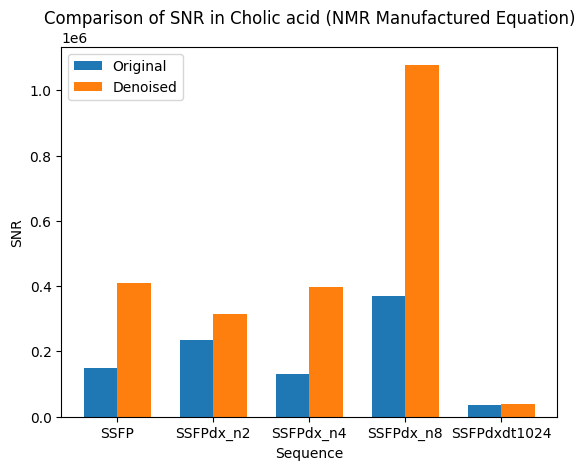

In [7]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_cholic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_cholic_acid['NMR Manufactured Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_cholic_acid['NMR Manufactured Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_cholic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cholic acid (NMR Manufactured Equation)')
plt.legend()
plt.show()

SNR Mean Equation

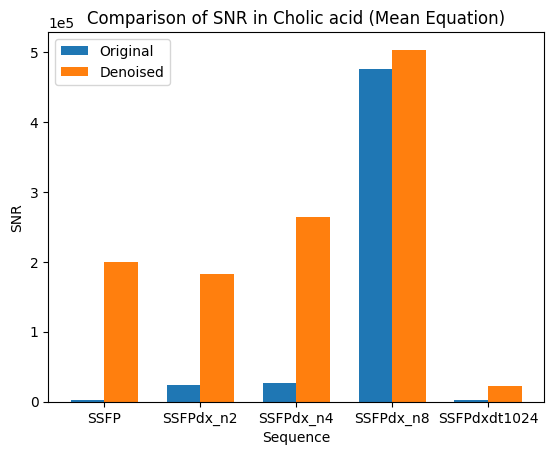

In [8]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_cholic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_cholic_acid['Mean Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_cholic_acid['Mean Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_cholic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cholic acid (Mean Equation)')
plt.legend()
plt.show()

SNR RMS Equation

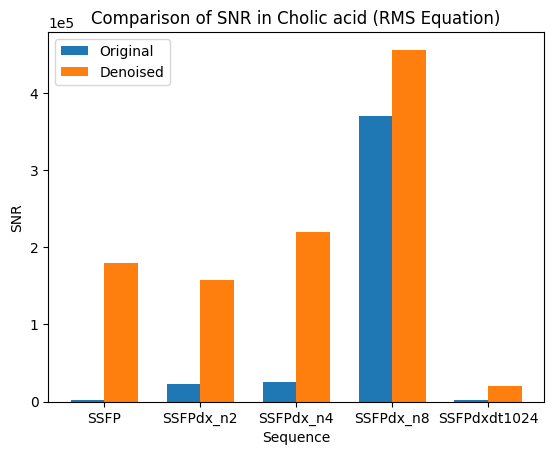

In [9]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_cholic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_cholic_acid['RMS Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_cholic_acid['RMS Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_cholic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cholic acid (RMS Equation)')
plt.legend()
plt.show()

SNR Max Equation

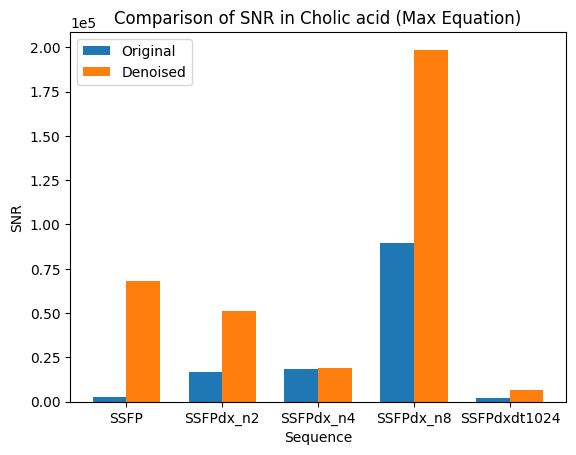

In [10]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_cholic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_cholic_acid['Max Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_cholic_acid['Max Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_cholic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cholic acid (Max Equation)')
plt.legend()
plt.show()

###For Cyclosporine:

In [11]:
#Calculating SNR for each sequence
snr_cyclosporine=pd.concat([
snr_data('Cyclosporine','SSFP','Seq1_cyclosporine_70°.csv',3,0.01,9,0,(10.0,16.0),13,4),
snr_data('Cyclosporine','SSFPdx_n2','Seq2_cyclosporine_70°.csv',5,0.04,9,0,(10.0,16.0),29,4),
snr_data('Cyclosporine','SSFPdx_n4','Seq3_cyclosporine_70°.csv',5,0.05,9,0,(10.0,16.0),29,4),
snr_data('Cyclosporine','SSFPdx_n8','Seq4_cyclosporine_70°.csv',5,0.05,9,0,(10.0,16.0),29,4),
snr_data('Cyclosporine','SSFPdxdt1024','Seq5_cyclosporine_65°.csv',4,0.09,9,0,(10.0,16.0),29,4),
])
snr_cyclosporine.reset_index(drop=True,inplace=True)

# Convert relevant columns to numeric to ensure correct plotting behavior
for col in snr_cyclosporine.columns:
    if col != 'Sequence': # Skip the 'Sequence' column as it is a string
        snr_cyclosporine[col] = pd.to_numeric(snr_cyclosporine[col])

snr_cyclosporine

,Sequence,NMR Manufactured Equation (Raw),NMR Manufactured Equation (Smoothed),Mean Equation (Raw),Mean Equation (Smoothed),RMS Equation (Raw),RMS Equation (Smoothed),Max Equation (Raw),Max Equation (Smoothed)
0,SSFP,48473.658971,52434.564362,62044.169234,46260.462784,47967.109147,34693.609185,10510.781984,7280.128675
1,SSFPdx_n2,28059.437553,310060.549247,2743.945677,307948.106841,2730.918890,218879.214244,2256.562420,17607.977518
2,SSFPdx_n4,34151.101298,278927.905203,2143.007514,371537.361720,2138.800719,223504.712559,1548.701714,17414.566802
3,SSFPdx_n8,24972.528849,299257.111395,36954.183815,311420.065867,24272.788269,216346.580521,2609.359520,17014.624462
4,SSFPdxdt1024,18078.302405,27690.787705,20218.130081,20043.391469,16138.810804,16443.832262,4513.693087,5237.964540


SNR NMR Manufactured Equation

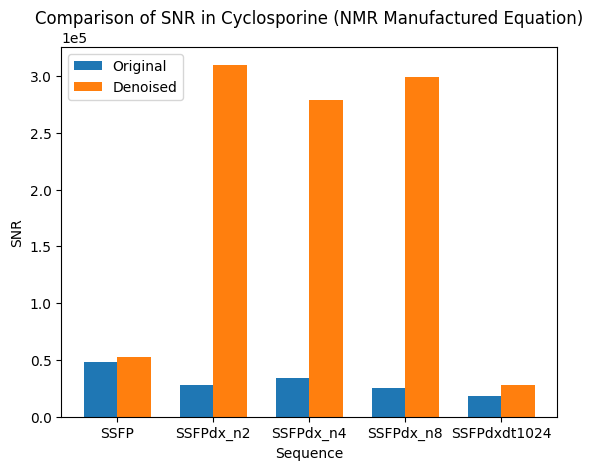

In [12]:
#Plotting:
bar_width=0.35
r=np.arange(len(snr_cyclosporine['Sequence']))

plt.bar(r-(bar_width/2),snr_cyclosporine['NMR Manufactured Equation (Raw)'],label='Original',width=bar_width)
plt.bar(r+(bar_width/2),snr_cyclosporine['NMR Manufactured Equation (Smoothed)'],label='Denoised',width=bar_width)
plt.xticks(r,snr_cyclosporine['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cyclosporine (NMR Manufactured Equation)')
plt.legend()
plt.show()

SNR Mean Equation

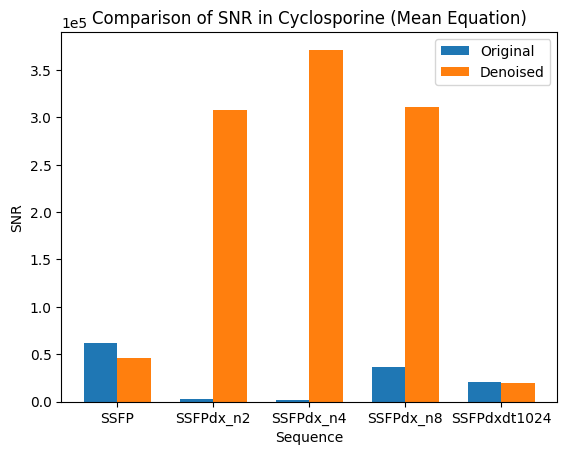

In [13]:
#Plotting:
bar_width=0.35
r=np.arange(len(snr_cyclosporine['Sequence']))

plt.bar(r-(bar_width/2),snr_cyclosporine['Mean Equation (Raw)'],label='Original',width=bar_width)
plt.bar(r+(bar_width/2),snr_cyclosporine['Mean Equation (Smoothed)'],label='Denoised',width=bar_width)
plt.xticks(r,snr_cyclosporine['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cyclosporine (Mean Equation)')
plt.legend()
plt.show()

SNR RMS Equation

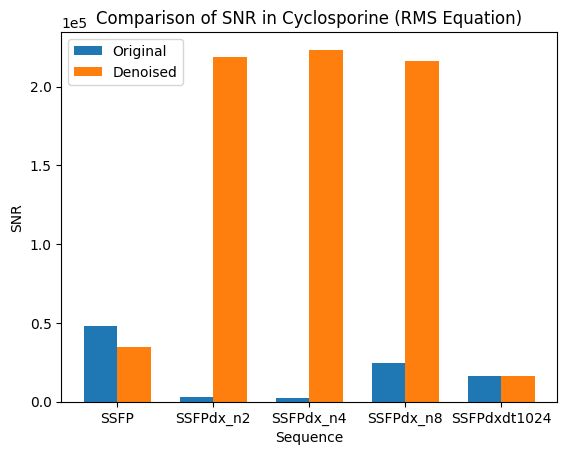

In [14]:
#Plotting:
bar_width=0.35
r=np.arange(len(snr_cyclosporine['Sequence']))

plt.bar(r-(bar_width/2),snr_cyclosporine['RMS Equation (Raw)'],label='Original',width=bar_width)
plt.bar(r+(bar_width/2),snr_cyclosporine['RMS Equation (Smoothed)'],label='Denoised',width=bar_width)
plt.xticks(r,snr_cyclosporine['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cyclosporine (RMS Equation)')
plt.legend()
plt.show()

SNR Max Equation

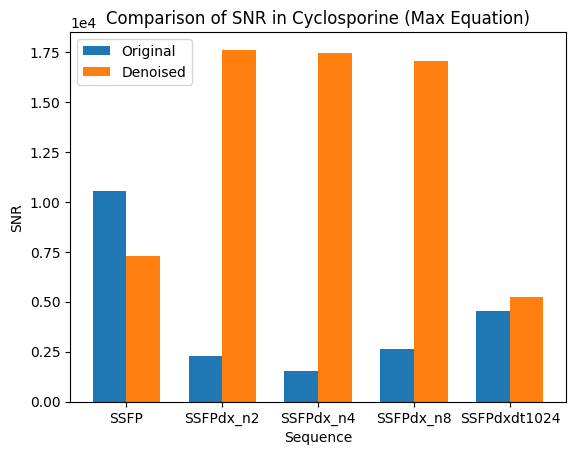

In [15]:
#Plotting:
bar_width=0.35
r=np.arange(len(snr_cyclosporine['Sequence']))

plt.bar(r-(bar_width/2),snr_cyclosporine['Max Equation (Raw)'],label='Original',width=bar_width)
plt.bar(r+(bar_width/2),snr_cyclosporine['Max Equation (Smoothed)'],label='Denoised',width=bar_width)
plt.xticks(r,snr_cyclosporine['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Cyclosporine (Max Equation)')
plt.legend()
plt.show()

###For Ethylbenzene

In [16]:
#Calculating SNR for each sequence
snr_EB=pd.concat([
snr_data('Ethylbenzene','SSFP','Seq1_EB_30°.csv',4,0.09,8,0,(8.00,14.30),17,2),
snr_data('Ethylbenzene','SSFPdx_n2','Seq2_EB_40°.csv',4,0.02,8,0,(8.00,14.30),29,5),
snr_data('Ethylbenzene','SSFPdx_n4','Seq3_EB_40°.csv',5,0.05,8,0,(8.00,14.30),21,3),
snr_data('Ethylbenzene','SSFPdx_n8','Seq4_EB_35°.csv',5,0.05,8,0,(8.00,14.30),25,4),
snr_data('Ethylbenzene','SSFPdxdt1024','Seq5_EB_40°.csv',2,0.1,8,0,(8.00,14.30),37,6)],
)
snr_EB.reset_index(drop=True,inplace=True)

# Convert relevant columns to numeric to ensure correct plotting behavior
for col in snr_EB.columns:
    if col != 'Sequence': # Skip the 'Sequence' column as it is a string
        snr_EB[col] = pd.to_numeric(snr_EB[col])

snr_EB

,Sequence,NMR Manufactured Equation (Raw),NMR Manufactured Equation (Smoothed),Mean Equation (Raw),Mean Equation (Smoothed),RMS Equation (Raw),RMS Equation (Smoothed),Max Equation (Raw),Max Equation (Smoothed)
0,SSFP,255010.749547,394258.409344,551728.250300,9.582686e+05,254931.642519,365625.554199,14708.230702,18544.997819
1,SSFPdx_n2,194682.683935,495666.393380,184993.242222,1.107513e+06,150768.237978,452486.620106,29926.915779,24501.775793
2,SSFPdx_n4,196328.032205,401048.371733,159479.842256,1.234915e+06,133011.661388,381641.712069,26261.199254,21439.945328
3,SSFPdx_n8,128603.251711,421356.428658,180288.174748,1.502497e+06,127611.962454,405869.363726,15644.625968,21725.091394
4,SSFPdxdt1024,106053.757683,203560.427445,58306.323888,2.074006e+05,54207.253415,147020.880755,10514.510449,16576.511739


SNR NMR Manufactured Equation

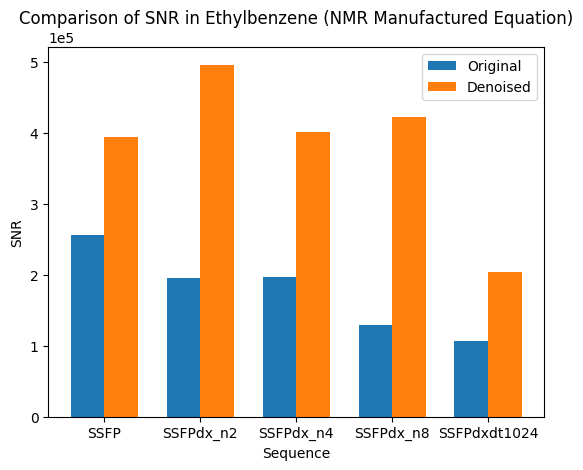

In [17]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_EB['Sequence']))

plt.bar(r-(bar_width/2),snr_EB['NMR Manufactured Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_EB['NMR Manufactured Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_EB['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Ethylbenzene (NMR Manufactured Equation)')
plt.legend()
plt.show()

SNR Mean Equation

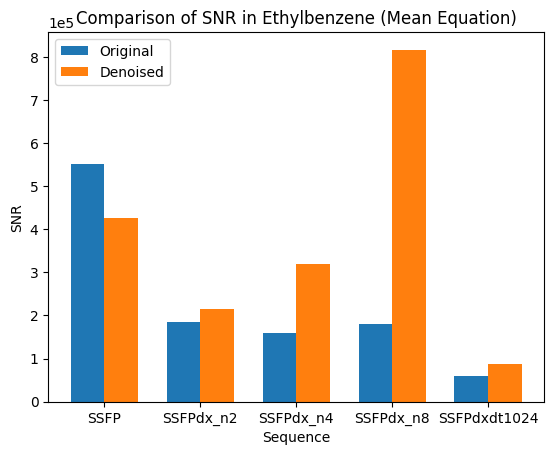

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_EB['Sequence']))

plt.bar(r-(bar_width/2),snr_EB['Mean Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_EB['Mean Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_EB['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Ethylbenzene (Mean Equation)')
plt.legend()
plt.show()

SNR RMS Equation

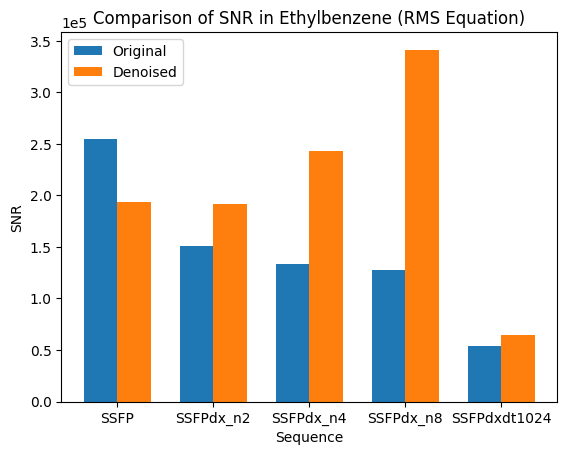

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_EB['Sequence']))

plt.bar(r-(bar_width/2),snr_EB['RMS Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_EB['RMS Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_EB['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Ethylbenzene (RMS Equation)')
plt.legend()
plt.show()

SNR Max Equation

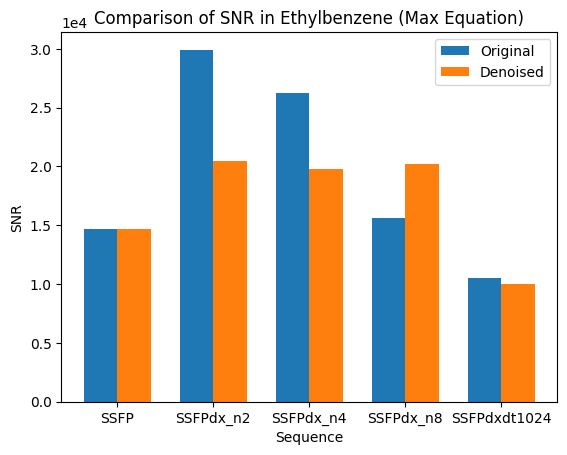

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_EB['Sequence']))

plt.bar(r-(bar_width/2),snr_EB['Max Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_EB['Max Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_EB['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Ethylbenzene (Max Equation)')
plt.legend()
plt.show()

###For Pamoic acid

In [ ]:
#Calculating SNR for each sequence
snr_pamoic_acid=pd.concat([
snr_data('Pamoic acid','SSFP','Seq1_pamoic acid_70°.csv',3,0.102,9,1,(-0.6,-0.5),27,4,),
snr_data('Pamoic acid','SSFPdx_n2',"Seq2_pamoic acid_60°.csv",4,0.06,9,1,(-0.6,-0.5),29,4),
snr_data('Pamoic acid','SSFPdx_n4','Seq3_pamoic acid_65°.csv',4,0.06,9,1,(-0.6,-0.5),29,5),
snr_data('Pamoic acid','SSFPdx_n8','Seq4_pamoic acid_65°.csv',4,0.06,9,1,(-0.6,-0.5),29,5),
snr_data('Pamoic acid','SSFPdxdt1024','Seq5_pamoic acid_55°.csv',4,0.06,9,1,(-0.6,-0.5),29,5)],
)
snr_pamoic_acid.reset_index(drop=True,inplace=True)

# Convert relevant columns to numeric to ensure correct plotting behavior
for col in snr_pamoic_acid.columns:
    if col != 'Sequence': # Skip the 'Sequence' column as it is a string
        snr_pamoic_acid[col] = pd.to_numeric(snr_pamoic_acid[col])

snr_pamoic_acid

,Sequence,NMR Manufactured Equation (Raw),NMR Manufactured Equation (Smoothed),Mean Equation (Raw),Mean Equation (Smoothed),RMS Equation (Raw),RMS Equation (Smoothed),Max Equation (Raw),Max Equation (Smoothed)
0,SSFP,11272.331109,235183.339150,607.455944,143249.010653,606.575823,124713.102862,537.330406,65119.481665
1,SSFPdx_n2,25928.876074,289199.027462,30511.851244,191602.737061,25905.189879,160504.054580,13011.908720,89068.596708
2,SSFPdx_n4,27355.622673,288673.902060,7883.382900,195056.972110,7575.105037,162421.809264,4954.724403,91097.493327
3,SSFPdx_n8,27741.143829,170229.633267,11908.911620,119052.384392,10943.179816,98109.981222,6246.019666,50527.971415
4,SSFPdxdt1024,5067.145046,38293.584757,861.350612,23647.049914,849.169311,20214.528272,616.828046,10268.000677


SNR NMR Manufactured Equation

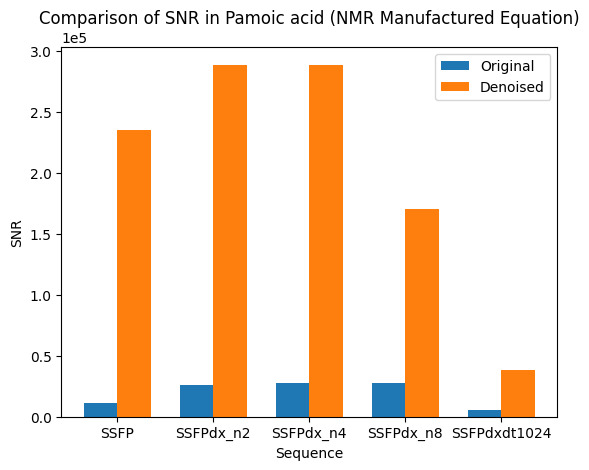

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_pamoic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_pamoic_acid['NMR Manufactured Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_pamoic_acid['NMR Manufactured Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_pamoic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Pamoic acid (NMR Manufactured Equation)')
plt.legend()
plt.show()

SNR Mean Equation

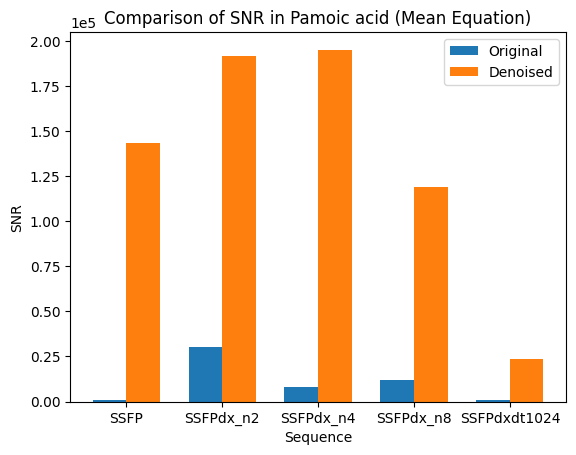

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_pamoic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_pamoic_acid['Mean Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_pamoic_acid['Mean Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_pamoic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Pamoic acid (Mean Equation)')
plt.legend()
plt.show()

SNR RMS Equation

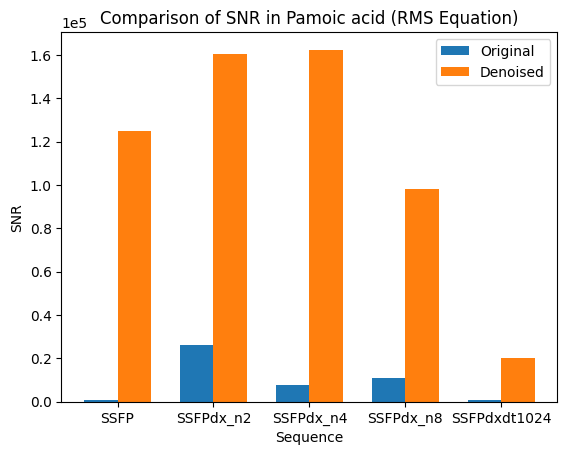

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_pamoic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_pamoic_acid['RMS Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_pamoic_acid['RMS Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_pamoic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Pamoic acid (RMS Equation)')
plt.legend()
plt.show()

SNR Max Equation

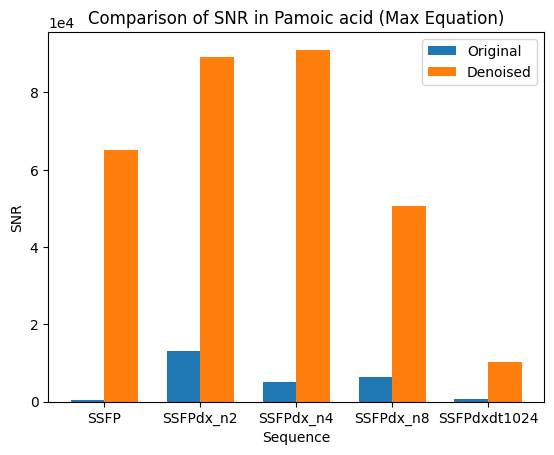

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_pamoic_acid['Sequence']))

plt.bar(r-(bar_width/2),snr_pamoic_acid['Max Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_pamoic_acid['Max Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_pamoic_acid['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Pamoic acid (Max Equation)')
plt.legend()
plt.show()

###For Xanthan Gum

In [ ]:
#Calculating SNR for each sequence
snr_XG=pd.concat([
snr_data('Xanthan Gum','SSFP','Seq1_XG_35°.csv',4,0.06,2.5,1.7,(-0.26,-0.235),33,2),
snr_data('Xanthan Gum','SSFPdx_n2','Seq2_XG_20°.csv',4,0.06,2.5,1.7,(-0.26,-0.235),47,3),
snr_data('Xanthan Gum','SSFPdx_n4','Seq3_XG_20°.csv',4,0.06,2.5,1.7,(-0.26,-0.235),47,3),
snr_data('Xanthan Gum','SSFPdx_n8','Seq4_XG_20°.csv',4,0.06,2.5,1.7,(-0.26,-0.235),33,2),
snr_data('Xanthan Gum','SSFPdxdt1024','Seq5_XG_30°.csv',4,0.06,2.5,1.7,(-0.26,-0.235),33,2)],
)
snr_XG.reset_index(drop=True,inplace=True)

# Convert relevant columns to numeric to ensure correct plotting behavior
for col in snr_XG.columns:
    if col != 'Sequence': # Skip the 'Sequence' column as it is a string
        snr_XG[col] = pd.to_numeric(snr_XG[col])

snr_XG

,Sequence,NMR Manufactured Equation (Raw),NMR Manufactured Equation (Smoothed),Mean Equation (Raw),Mean Equation (Smoothed),RMS Equation (Raw),RMS Equation (Smoothed),Max Equation (Raw),Max Equation (Smoothed)
0,SSFP,10735.835600,5.854972e+06,11532.281215,1.887875e+06,10114.350294,1.796781e+06,6158.169852,1.193641e+06
1,SSFPdx_n2,11796.962127,2.298993e+05,13030.160743,1.544317e+05,11746.044439,1.290446e+05,8029.055955,7.559224e+04
2,SSFPdx_n4,12301.659535,2.489418e+05,10612.174939,1.795267e+05,8629.669073,1.459880e+05,5162.029379,8.776421e+04
3,SSFPdx_n8,12495.903050,3.151358e+06,8117.962147,1.945845e+06,6807.542378,1.678807e+06,4278.353535,9.654624e+05
4,SSFPdxdt1024,9005.868374,1.115896e+05,9907.095046,7.051756e+04,8928.690755,5.966602e+04,5911.254748,3.485378e+04


SNR NMR Manufactured Equation

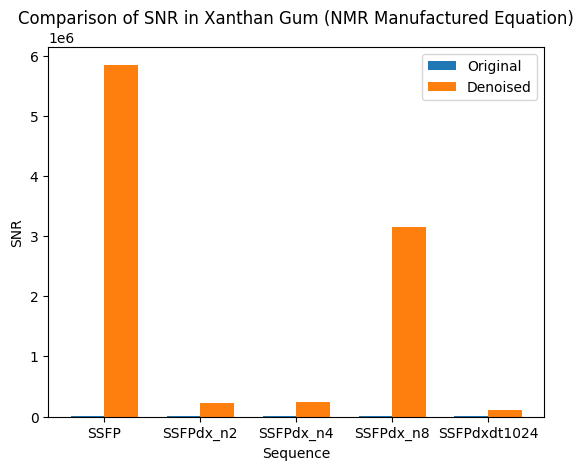

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_XG['Sequence']))

plt.bar(r-(bar_width/2),snr_XG['NMR Manufactured Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_XG['NMR Manufactured Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_XG['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Xanthan Gum (NMR Manufactured Equation)')
plt.legend()
plt.show()

SNR Mean Equation

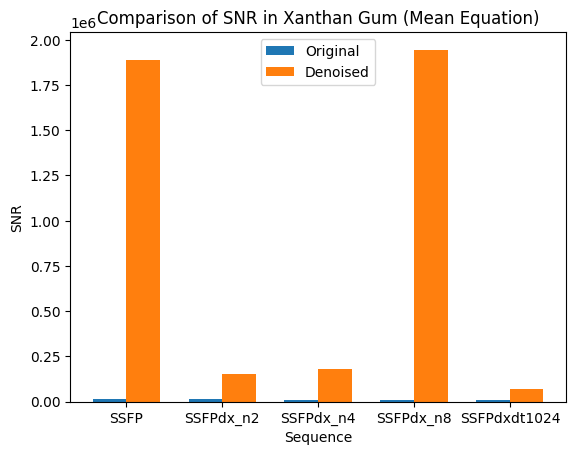

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_XG['Sequence']))

plt.bar(r-(bar_width/2),snr_XG['Mean Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_XG['Mean Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_XG['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Xanthan Gum (Mean Equation)')
plt.legend()
plt.show()

SNR RMS Equation

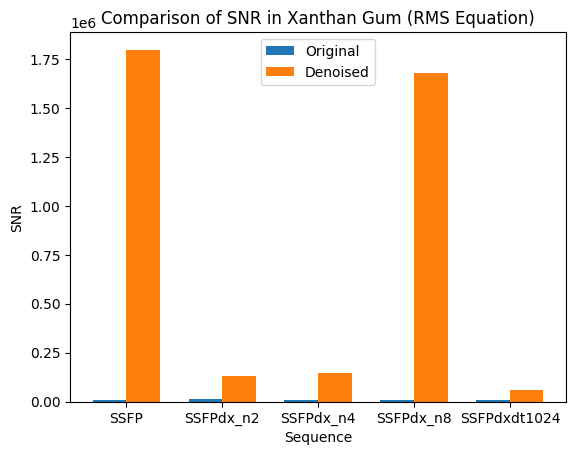

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_XG['Sequence']))

plt.bar(r-(bar_width/2),snr_XG['RMS Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_XG['RMS Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_XG['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Xanthan Gum (RMS Equation)')
plt.legend()
plt.show()

SNR Max Equation

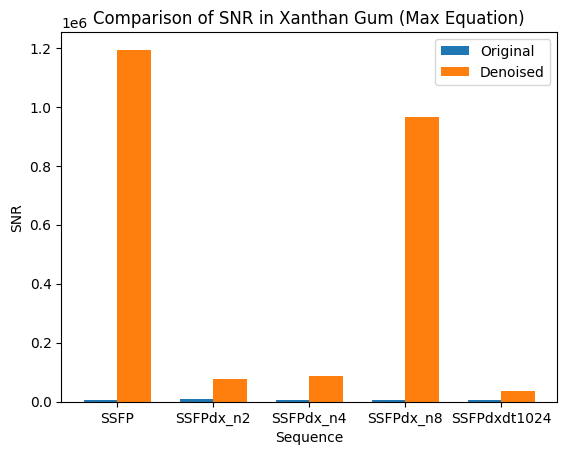

In [ ]:
#Plotting bar:
bar_width=0.35
r=np.arange(len(snr_XG['Sequence']))

plt.bar(r-(bar_width/2),snr_XG['Max Equation (Raw)'],width=bar_width,label='Original')
plt.bar(r+(bar_width/2),snr_XG['Max Equation (Smoothed)'],width=bar_width,label='Denoised')
plt.xticks(r,snr_XG['Sequence'])
plt.xlabel('Sequence')
plt.ylabel('SNR')
plt.ticklabel_format(axis='y',style='sci',scilimits=(0,0))
plt.title('Comparison of SNR in Xanthan Gum (Max Equation)')
plt.legend()
plt.show()